# Task 2: Learn-Then-Optimize

Demand $d$ is known; prices $p$ are uncertain. We first *learn* a price model
$p_t \mid z \sim \mathcal{N}\!\big(\mu_t(z;\theta), \hat\sigma_t^2\big)$ (Sub-task 2.1),
then *optimize* the battery schedule with the predicted prices and compare against the
hindsight solution (Sub-task 2.2).

The optimization problem is the one from Task 1.5:

$$
Q(B,\xi) = \min_{x,s} \; \sum_{t=0}^{23} p_t x_t
\quad\text{s.t.}\quad s_t = s_{t-1} + x_t - d_t,\;\; 0 \le s_t \le B,\;\; x_t \ge 0,\;\; s_{-1}=0.
$$

The objective is **linear in $p$** and the feasible set **does not depend on $p$**, so minimising
expected cost only requires the conditional *mean* price in each hour. The variance
$\hat\sigma_t^2$ is therefore used for (a) reporting prediction uncertainty, (b) the lognormal
mean correction in 2.2, and (c) the SAA sanity check - not for the decision itself.

## Setup

In [1]:
import copy
from datetime import datetime as dt
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytz
from pandas.tseries.holiday import USFederalHolidayCalendar
from scipy.stats import norm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [2]:
ROOT = Path.cwd().parent                    # task_2/
PRICE_FILE = ROOT / "data" / "storage_data.csv"
DEMAND_FILE = (
    ROOT.parent / "task_1.5" / "data" / "demand_data"
    / "03_whole-facility_profiles" / "inference" / "simulated_data"
    / "inference_1MW_283nodes_60u_power.csv"
)
VIS_DIR = ROOT / "visualizations"
VIS_DIR.mkdir(exist_ok=True)

T = 24                     # hours per day
SEED = 0
TZ = "America/New_York"    # market timezone, for the DST calendar feature

# Price model: "lognormal" models log p (as in Donti et al.), "gaussian" models p directly.
PRICE_MODEL = "lognormal"

# Chronological split fractions (days, in time order - never shuffle)
TRAIN_FRAC, VAL_FRAC = 0.70, 0.10

# Outlier filter on daily price vectors
PRICE_MIN, PRICE_MAX = 0.0, 500.0

# Battery
B_DEFAULT = 5.0                       # MWh
B_VALUES = np.linspace(0, 15, 31)     # for the sensitivity sweep

torch.manual_seed(SEED)
np.random.seed(SEED)

---
# Sub-task 2.1: Price prediction

Build $\mu_t(z;\theta)$ for $t = 1,\dots,24$ by minimising MSE, then estimate one residual
variance $\hat\sigma_t^2$ per hour (fixed across days).

### Step 1 - Load the hourly data and pivot to daily 24-vectors

`storage_data.csv` has one row per hour with `datetime, da_price, load_forecast, temp_dca`.
Pivot each column to a `(date x hour)` frame, forward/backward fill the few gaps, and keep only
days with all 24 hours.

In [3]:
def load_daily_frames(price_file: Path) -> dict[str, pd.DataFrame]:
    """Return {"price": df, "load": df, "temp": df}, each indexed by date with 24 hour columns."""
    #  - pd.read_csv(price_file, parse_dates=["datetime"]); add "date" and "hour" columns
    #  - for each of da_price / load_forecast / temp_dca: df.pivot(index="date", columns="hour")
    #  - fill gaps along the hour axis (bfill then ffill), drop incomplete days
    
    price_df = pd.read_csv(price_file, parse_dates=["datetime"])
    price_df["date"] = price_df["datetime"].dt.date
    price_df["hour"] = price_df["datetime"].dt.hour

    cols = {"price": "da_price", "load": "load_forecast", "temp": "temp_dca"}

    frames = {}

    for name, col in cols.items():
        wide = price_df.pivot(index="date", columns="hour", values=col).sort_index().astype(float)
        wide = wide.bfill(axis=1).ffill(axis=1)
        frames[name] = wide.dropna(how="any")

    common = frames["price"].index

    for f in frames.values():
        common = common.intersection(f.index)
    return {k: v.loc[common] for k, v in frames.items()}    

### Step 2 - Filter outliers and choose the prediction target

In [4]:
def filter_and_transform(frames: dict[str, pd.DataFrame], model: str = PRICE_MODEL):
    """Drop outlier days, align all frames on the surviving dates; return (prices, target, frames)."""
    #  - mask days with any p_t <= PRICE_MIN or p_t > PRICE_MAX and drop them
    #  - reindex load/temp onto the surviving price index
    #  - target = np.log(prices) if model == "lognormal" else prices
    ...

    prices = frames["price"]

    valid_range = (prices > PRICE_MIN) & (prices <= PRICE_MAX)
    keep = valid_range.all(axis=1)
    
    prices = prices.loc[keep]

    frames = {k: v.loc[keep] for k, v in frames.items()}

    if model == "lognormal":
        target = np.log(prices)
    elif model == "gaussian":
        target = prices.copy()
    else:
        raise ValueError(f"Unknown model: {model}")

    return prices, target, frames

### Step 3 - Build the features $z$ and standardise

Everything in $z$ must be known before day $i$ begins: yesterday's prices, today's published load
forecast, temperatures (lagged actual + forecast, with polynomial terms), and calendar variables.
Standardise with **training-set** statistics only, so the validation/test days stay out of sample.

In [5]:
def build_calendar_features(dates: pd.Index) -> pd.DataFrame:
    """weekend, US federal holiday, DST flag, cos/sin of day-of-year."""
    tz = pytz.timezone(TZ)
    holidays = USFederalHolidayCalendar().holidays(start=min(dates), end=max(dates))
    holiday_dates = {h.date() for h in holidays.to_pydatetime()}

    def is_dst(d):
        return tz.localize(dt.combine(d, dt.min.time())).dst().seconds > 0

    def doy_angle(d):
        return d.timetuple().tm_yday / 365.0 * 2 * np.pi

    return pd.DataFrame(
        {
            "weekend": [d.isoweekday() >= 6 for d in dates],
            "holiday": [d in holiday_dates for d in dates],
            "dst": [is_dst(d) for d in dates],
            "cos_doy": [np.cos(doy_angle(d)) for d in dates],
            "sin_doy": [np.sin(doy_angle(d)) for d in dates],
        },
        index=dates,
    ).astype(float)


def build_features(frames: dict[str, pd.DataFrame], target: pd.DataFrame):
    """Return (Z, Y, dates): Z is (n_days, 173), Y is (n_days, 24), both float arrays.

    Row i predicts day i from information available before it starts: day i-1 outturns
    (".iloc[:-1]") plus day i forecasts and calendar variables (".iloc[1:]").
    """
    load, temp = frames["load"], frames["temp"]

    prev_price = target.iloc[:-1].to_numpy()     # yesterday's (log) prices
    load_today = load.iloc[1:].to_numpy()        # today's published load forecast
    temp_prev = temp.iloc[:-1].to_numpy()        # yesterday's temperatures
    temp_today = temp.iloc[1:].to_numpy()        # today's temperatures
    dates = target.index[1:]
    calendar = build_calendar_features(dates).to_numpy()

    Z = np.hstack(
        [
            prev_price,                                      # 24
            load_today,                                      # 24
            temp_prev, temp_prev ** 2,                       # 48
            temp_today, temp_today ** 2, temp_today ** 3,    # 72
            calendar,                                        #  5
        ]
    ).astype(np.float64)
    Y = target.iloc[1:].to_numpy().astype(np.float64)
    return Z, Y, dates


def standardise(Z_train, *others):
    """Standardise with train mean/std; apply the same transform to the other splits.

    Call this *after* the chronological split in Step 4, never before - fitting the
    scaler on all days would leak validation/test information into training.
    """
    mean = Z_train.mean(axis=0)
    std = Z_train.std(axis=0)
    std = np.where(std == 0, 1.0, std)    # guard constant columns
    return tuple((Z - mean) / std for Z in (Z_train, *others))

### Step 4 - Chronological train / validation / test split

The validation split does double duty: early stopping in Step 6 and the variance estimate in
Step 8. The test split is touched only in 2.2.

In [6]:
def split_chronological(Z, Y, dates, prices, train_frac=TRAIN_FRAC, val_frac=VAL_FRAC):
    """Return {"train"/"val"/"test": {"Z", "Y", "dates", "prices"}}, in time order.

    The cuts are by position in time, never random: day i's features contain day i-1's
    prices, so a random split would put a day's label in train and a copy of it in test.
    """
    n = len(Z)
    a = int(n * train_frac)
    b = int(n * (train_frac + val_frac))
    assert 0 < a < b < n, f"empty split for train_frac={train_frac}, val_frac={val_frac}"

    prices = prices.loc[dates].to_numpy()

    cuts = {"train": slice(0, a), "val": slice(a, b), "test": slice(b, n)}
    splits = {
        name: {"Z": Z[s], "Y": Y[s], "dates": dates[s], "prices": prices[s]}
        for name, s in cuts.items()
    }

    # Step 3's scaler, fitted on the training days only - has to happen after the cuts.
    splits["train"]["Z"], splits["val"]["Z"], splits["test"]["Z"] = standardise(
        splits["train"]["Z"], splits["val"]["Z"], splits["test"]["Z"]
    )
    return splits


def make_loaders(splits, batch_size=64):
    """Wrap each split in a TensorDataset/DataLoader (shuffle only the train loader)."""
    loaders = {}
    for name, s in splits.items():
        dataset = TensorDataset(
            torch.tensor(s["Z"], dtype=torch.float32),
            torch.tensor(s["Y"], dtype=torch.float32),
        )
        is_train = name == "train"
        loaders[name] = DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=is_train,      # only within the training set; the split stays chronological
            drop_last=is_train,    # BatchNorm1d errors on a final batch of size 1
        )
    return loaders

### Step 5 - The network $\mu_t(z;\theta)$

Following `inspo/model_classes.py`: a linear layer initialised at the least-squares solution, plus
a `[200, 200]` MLP (Linear -> BatchNorm -> ReLU -> Dropout) whose output is added to it. 24
outputs, one mean per hour.

In [7]:
import operator
from functools import reduce


class PriceNet(nn.Module):
    """mu(z; theta): (n, n_feat) -> (n, 24)."""

    def __init__(self, Z_train, Y_train, hidden=(200, 200)):
        super().__init__()
        n_feat, n_out = Z_train.shape[1], Y_train.shape[1]

        # Linear layer initialised at the least-squares solution.
        X_ = np.hstack([Z_train, np.ones((Z_train.shape[0], 1))])
        Theta = np.linalg.lstsq(X_, Y_train, rcond=None)[0]
        self.lin = nn.Linear(n_feat, n_out)
        with torch.no_grad():
            self.lin.weight.copy_(torch.tensor(Theta[:-1, :].T, dtype=torch.float32))
            self.lin.bias.copy_(torch.tensor(Theta[-1, :], dtype=torch.float32))

        # Non-linear correction: Linear -> BatchNorm -> ReLU -> Dropout blocks.
        layer_sizes = [n_feat] + list(hidden)
        layers = reduce(
            operator.add,
            [[nn.Linear(a, b), nn.BatchNorm1d(b), nn.ReLU(), nn.Dropout(p=0.2)]
             for a, b in zip(layer_sizes[:-1], layer_sizes[1:])],
        )
        layers.append(nn.Linear(layer_sizes[-1], n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.lin(z) + self.net(z)

### Step 6 - Train by minimising MSE

Adam, MSE loss, early stopping on validation MSE, restore the best state.

In [8]:
def evaluate(model, loader, loss_fn):
    """Sample-weighted mean loss over a loader, no gradients."""
    model.eval()
    total, m = 0.0, 0
    with torch.no_grad():
        for Zb, Yb in loader:
            total += loss_fn(model(Zb), Yb).item() * Zb.size(0)
            m += Zb.size(0)
    return total / m


def train_mse(model, loaders, lr=1e-3, max_epochs=500, patience=20, verbose=True):
    """Train mu(z; theta) on MSE; return (model, history) with the best-validation weights."""
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    best_val, best_epoch = float("inf"), 0
    best_state = copy.deepcopy(model.state_dict())
    history = {"train": [], "val": []}

    for epoch in range(max_epochs):
        model.train()
        total, m = 0.0, 0
        for Zb, Yb in loaders["train"]:
            opt.zero_grad()
            loss = loss_fn(model(Zb), Yb)
            loss.backward()
            opt.step()
            total += loss.item() * Zb.size(0)
            m += Zb.size(0)
        train_loss = total / m

        # Validation only - the test split stays untouched until 2.2.
        val_loss = evaluate(model, loaders["val"], loss_fn)
        history["train"].append(train_loss)
        history["val"].append(val_loss)

        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            # deepcopy: state_dict() aliases the live tensors, which Adam updates in place
            best_state = copy.deepcopy(model.state_dict())

        if verbose and epoch % 10 == 0:
            print(f"epoch {epoch:4d}  train {train_loss:.5f}  val {val_loss:.5f}")

        if epoch - best_epoch >= patience:
            if verbose:
                print(f"early stop at epoch {epoch} (best {best_epoch}, val {best_val:.5f})")
            break

    model.load_state_dict(best_state)
    history["best_epoch"], history["best_val"] = best_epoch, best_val
    return model, history

In [9]:
# Steps 1-6 end to end.
torch.manual_seed(SEED)
np.random.seed(SEED)

frames = load_daily_frames(PRICE_FILE)                    # 1. hourly rows -> daily 24-vectors
prices, target, frames = filter_and_transform(frames)     # 2. drop outlier days, log transform
Z, Y, dates = build_features(frames, target)              # 3. features z and labels
splits = split_chronological(Z, Y, dates, prices)         # 4. chronological split + standardise
loaders = make_loaders(splits)                            #    torch loaders

for name in ("train", "val", "test"):
    s = splits[name]
    print(f"{name:5s} {len(s['dates']):5d} days  {s['dates'][0]} -> {s['dates'][-1]}  Z{s['Z'].shape}")

model = PriceNet(splits["train"]["Z"], splits["train"]["Y"])   # 5. mu(z; theta)
model, history = train_mse(model, loaders)                     # 6. MSE + early stopping

print(f"\ntrained {len(history['train'])} epochs, best epoch {history['best_epoch']}, "
      f"val MSE {history['best_val']:.5f} (log-price units)")

train  1528 days  2011-01-04 -> 2015-03-17  Z(1528, 173)
val     218 days  2015-03-18 -> 2015-10-21  Z(218, 173)
test    437 days  2015-10-22 -> 2016-12-31  Z(437, 173)
epoch    0  train 0.09594  val 0.02866
epoch   10  train 0.01316  val 0.01894
epoch   20  train 0.01053  val 0.01814
epoch   30  train 0.00929  val 0.01916
early stop at epoch 32 (best 12, val 0.01697)

trained 33 epochs, best epoch 12, val MSE 0.01697 (log-price units)


Essentially, we trained for max of 60 epochs, but the best one is at epoch 30, which had a performance on the validation set of 0.01916

### Step 7 - Prediction accuracy

Per-hour RMSE/MAE on the test split, against two cheap baselines: persistence (yesterday's prices)
and the hour-of-day training mean. Report in price units - if the model was fitted on $\log p$,
also report the error after converting back to \$/MWh.

In [10]:
def predict(model, Z) -> np.ndarray:
    """mu for every day in Z (model.eval(), torch.no_grad())."""
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(Z, dtype=torch.float32)).numpy().astype(np.float64)


def per_hour_errors(pred, actual) -> pd.DataFrame:
    """RMSE and MAE per hour t."""
    resid = pred - actual
    return pd.DataFrame(
        {"rmse": np.sqrt((resid ** 2).mean(axis=0)), "mae": np.abs(resid).mean(axis=0)},
        index=pd.RangeIndex(actual.shape[1], name="hour"),
    )


def baseline_forecasts(splits, target, which="test") -> dict[str, np.ndarray]:
    """Cheap reference forecasts on the chosen split, same shape and units as Y."""
    dates = splits[which]["dates"]
    persistence = target.shift(1).loc[dates].to_numpy()          # yesterday's log prices
    hour_mean = np.tile(splits["train"]["Y"].mean(axis=0), (len(dates), 1))
    return {"persistence": persistence, "hour_mean": hour_mean}


def error_summary(forecasts, Y_true, p_true) -> pd.DataFrame:
    """One row per forecast: error in log units and in $/MWh.

    The dollar columns use exp(mu), the *median* of the fitted lognormal. Step 9
    adds the exp(sigma^2 / 2) correction that turns it into the mean, which is what
    the LP in 2.2 needs; here we are measuring prediction accuracy, not cost.
    """
    rows = {}
    for name, pred in forecasts.items():
        resid_log = pred - Y_true
        resid_usd = np.exp(pred) - p_true
        rows[name] = {
            "MSE (log)": (resid_log ** 2).mean(),
            "RMSE (log)": np.sqrt((resid_log ** 2).mean()),
            "RMSE ($/MWh)": np.sqrt((resid_usd ** 2).mean()),
            "MAE ($/MWh)": np.abs(resid_usd).mean(),
            "MAPE (%)": 100 * np.abs(resid_usd / p_true).mean(),
        }
    return pd.DataFrame(rows).T

             MSE (log)  RMSE (log)  RMSE ($/MWh)  MAE ($/MWh)  MAPE (%)
PriceNet        0.0135      0.1162        4.0927       2.5241    9.0065
persistence     0.0345      0.1856        6.2586       3.8235   13.1237
hour_mean       0.1813      0.4258       12.8061      11.3064   47.9033


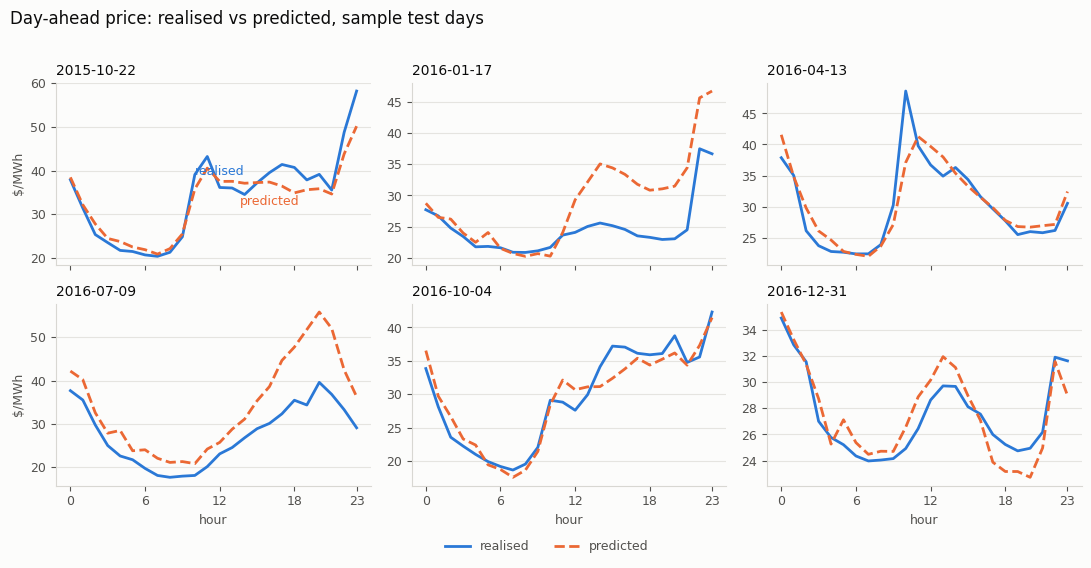

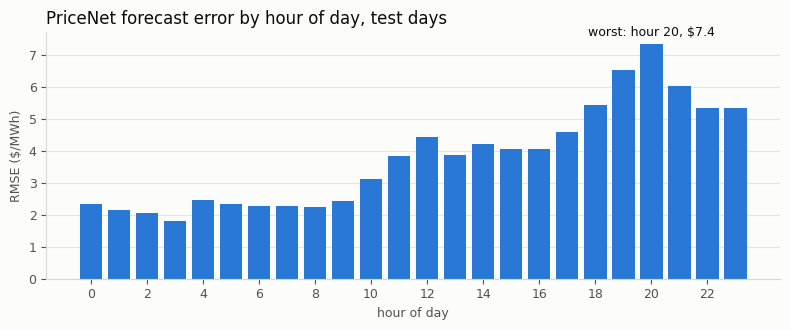

In [11]:
SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
SERIES = {"realised": "#2a78d6", "predicted": "#eb6834"}
SER = {"hind": "#2a78d6", "pred": "#eb6834", "nobat": "#1baf7a"}   # 2.2 series


def _style(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#d8d7d2")
    ax.tick_params(colors=INK_MUTED, labelsize=9)


def plot_sample_days(mu, p_true, dates, n=6, path=None):
    """Realised vs predicted price curves for n test days spread across the split."""
    idx = np.linspace(0, len(dates) - 1, n).astype(int)
    fig, axes = plt.subplots(2, n // 2, figsize=(11, 5.6), sharex=True, facecolor=SURFACE)
    hours = np.arange(p_true.shape[1])

    for k, (ax, i) in enumerate(zip(axes.ravel(), idx)):
        _style(ax)
        ax.plot(hours, p_true[i], color=SERIES["realised"], lw=2, label="realised")
        ax.plot(hours, np.exp(mu[i]), color=SERIES["predicted"], lw=2, ls="--", label="predicted")
        ax.set_title(str(dates[i]), fontsize=10, color=INK, loc="left")
        if k == 0:   # direct labels, so identity is never colour-alone
            ax.annotate("realised", (hours[12], p_true[i, 12]), color=SERIES["realised"],
                        fontsize=9, ha="center", va="bottom", xytext=(0, 7),
                        textcoords="offset points")
            ax.annotate("predicted", (hours[16], np.exp(mu[i, 16])), color=SERIES["predicted"],
                        fontsize=9, ha="center", va="top", xytext=(0, -9),
                        textcoords="offset points")
        if k >= n // 2:
            ax.set_xlabel("hour", fontsize=9, color=INK_MUTED)
        if k % (n // 2) == 0:
            ax.set_ylabel("$/MWh", fontsize=9, color=INK_MUTED)
        ax.set_xticks([0, 6, 12, 18, 23])

    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False,
               fontsize=9, labelcolor=INK_MUTED, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle("Day-ahead price: realised vs predicted, sample test days",
                 fontsize=12, color=INK, x=0.012, ha="left")
    fig.tight_layout(rect=(0, 0.03, 1, 0.97))
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


def plot_per_hour_rmse(err_usd, path=None):
    """Per-hour RMSE in $/MWh - one series, so the title names it and no legend is needed."""
    fig, ax = plt.subplots(figsize=(8, 3.4), facecolor=SURFACE)
    _style(ax)
    ax.bar(err_usd.index, err_usd["rmse"], width=0.8, color=SERIES["realised"])
    ax.set_xlabel("hour of day", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("RMSE ($/MWh)", fontsize=9, color=INK_MUTED)
    ax.set_xticks(range(0, 24, 2))
    worst = int(err_usd["rmse"].idxmax())
    ax.annotate(f"worst: hour {worst}, ${err_usd['rmse'].max():.1f}",
                (worst, err_usd["rmse"].max()), fontsize=9, color=INK,
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
    ax.set_title("PriceNet forecast error by hour of day, test days",
                 fontsize=12, color=INK, loc="left")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


mu_test = predict(model, splits["test"]["Z"])
Y_test, p_true = splits["test"]["Y"], splits["test"]["prices"]
test_dates = splits["test"]["dates"]

forecasts = {"PriceNet": mu_test, **baseline_forecasts(splits, target)}
summary = error_summary(forecasts, Y_test, p_true)
print(summary.round(4).to_string())

err_usd = per_hour_errors(np.exp(mu_test), p_true)
plot_sample_days(mu_test, p_true, test_dates, path=VIS_DIR / "price_predictions.png")
plot_per_hour_rmse(err_usd, path=VIS_DIR / "per_hour_rmse.png")
plt.show()

### Step 8 - Residual variance $\hat\sigma_t^2$

One variance per hour, assumed fixed across days, estimated from the residuals
$p_t - \mu_t(z;\theta)$ on the **validation** split (train residuals would understate it, test
residuals would leak). In the lognormal case these are residuals of $\log p$.

In [12]:
def estimate_variance(mu_val, Y_val) -> np.ndarray:
    """sigma_hat^2 per hour: mean over validation days of (Y - mu)**2, shape (24,)."""
    return ((Y_val - mu_val) ** 2).mean(axis=0)


# Validation residuals: unseen by the weights, so no degrees-of-freedom correction is needed.
mu_val = predict(model, splits["val"]["Z"])
sigma2 = estimate_variance(mu_val, splits["val"]["Y"])

print("sigma_hat per hour (log units):")
print(pd.Series(np.sqrt(sigma2), index=pd.RangeIndex(T, name="hour")).round(3).to_string())
print("\nmean validation residual %+.4f (bias, absorbed into sigma_hat^2)"
      % (splits["val"]["Y"] - mu_val).mean())

sigma_hat per hour (log units):
hour
0     0.092
1     0.065
2     0.082
3     0.065
4     0.109
5     0.101
6     0.130
7     0.156
8     0.184
9     0.207
10    0.227
11    0.165
12    0.100
13    0.094
14    0.103
15    0.100
16    0.101
17    0.119
18    0.134
19    0.141
20    0.149
21    0.136
22    0.111
23    0.101

mean validation residual -0.0216 (bias, absorbed into sigma_hat^2)


### Step 9 - The fitted price distribution

$$
\text{Gaussian:}\quad p_t \mid z \sim \mathcal{N}\big(\mu_t(z;\theta), \hat\sigma_t^2\big)
\qquad
\text{Lognormal:}\quad \log p_t \mid z \sim \mathcal{N}\big(\mu_t(z;\theta), \hat\sigma_t^2\big)
$$

Under the lognormal model the mean price is
$\mathbb{E}[p_t \mid z] = \exp(\mu_t + \hat\sigma_t^2/2)$, **not** $\exp(\mu_t)$ - this is the
number 2.2 feeds to the LP.

In [13]:
def expected_price(mu, sigma2, model: str = PRICE_MODEL) -> np.ndarray:
    """E[p | z] in $/MWh: mu for the Gaussian model, exp(mu + sigma2/2) for the lognormal."""
    if model == "lognormal":
        return np.exp(mu + sigma2 / 2.0)
    if model == "gaussian":
        return np.asarray(mu, dtype=float)
    raise ValueError(f"unknown price model: {model!r}")


def sample_prices(mu, sigma2, n_samples, rng, model: str = PRICE_MODEL) -> np.ndarray:
    """Draw (n_samples, 24) price paths for one day - used by the SAA check in 2.2."""
    mu = np.asarray(mu, dtype=float).ravel()
    draws = rng.normal(loc=mu, scale=np.sqrt(sigma2), size=(n_samples, mu.size))
    if model == "lognormal":
        return np.exp(draws)
    if model == "gaussian":
        return draws          # can go negative; the lognormal model cannot
    raise ValueError(f"unknown price model: {model!r}")


# This is the quantity 2.2 feeds to the LP.
mu_test = predict(model, splits["test"]["Z"])
p_hat_test = expected_price(mu_test, sigma2)
p_true_test = splits["test"]["prices"]

print("correction factor exp(sigma2/2): min %.4f  max %.4f" %
      (np.exp(sigma2 / 2).min(), np.exp(sigma2 / 2).max()))
print("mean median forecast exp(mu)        $%.3f" % np.exp(mu_test).mean())
print("mean  mean  forecast exp(mu+s2/2)   $%.3f  (+%.2f%%)" %
      (p_hat_test.mean(), 100 * (p_hat_test.mean() / np.exp(mu_test).mean() - 1)))
print("mean realised price                 $%.3f" % p_true_test.mean())

# The draws must average to expected_price - a check on both functions at once.
rng = np.random.default_rng(SEED)
paths = sample_prices(mu_test[0], sigma2, 10000, rng)
print("\n10k draws for day 0 vs expected_price: max |diff| $%.4f"
      % np.abs(paths.mean(axis=0) - p_hat_test[0]).max())

correction factor exp(sigma2/2): min 1.0021  max 1.0262
mean median forecast exp(mu)        $28.782
mean  mean  forecast exp(mu+s2/2)   $29.014  (+0.81%)
mean realised price                 $27.618

10k draws for day 0 vs expected_price: max |diff| $0.0690


### Step 10 - Calibration check

The Gaussian/lognormal assumption is an assumption, so check it: empirical coverage of the nominal
90% interval per hour, and a PIT histogram (flat if the model is calibrated).

mean coverage   val 0.914   test 0.918   (nominal 0.90)
test coverage   min 0.835 (hour 13)   max 0.986 (hour 0)
PIT mean 0.389 (uniform 0.500)   PIT std 0.244 (uniform 0.289)


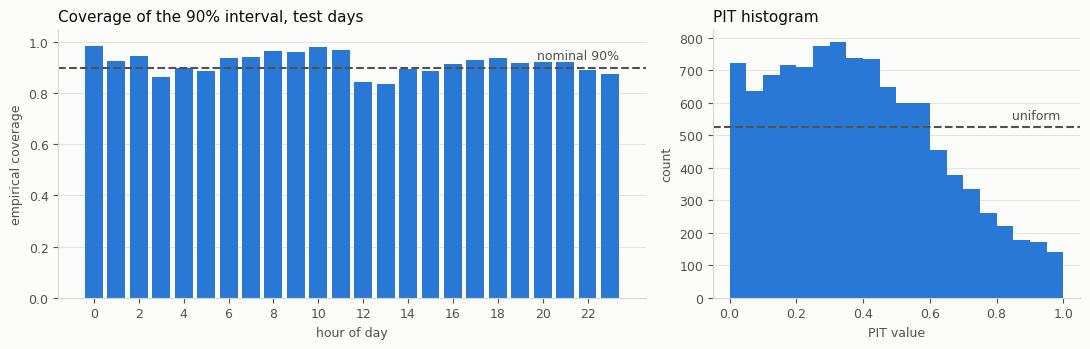

In [14]:
def calibration(mu, sigma2, Y_true, level=0.90):
    """Per-hour coverage of the central `level` interval, plus PIT values.

    Computed in the space the model was fitted in (log price for the lognormal), where
    the assumption is Gaussian - equivalent to applying the lognormal CDF to prices.
    """
    sigma = np.sqrt(sigma2)
    z = norm.ppf(0.5 + level / 2)
    inside = (Y_true >= mu - z * sigma) & (Y_true <= mu + z * sigma)
    pit = norm.cdf((Y_true - mu) / sigma)
    return pd.Series(inside.mean(axis=0), index=pd.RangeIndex(T, name="hour")), pit


def plot_calibration(coverage, pit, level=0.90, path=None):
    """Left: per-hour coverage vs nominal. Right: PIT histogram vs uniform."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), facecolor=SURFACE,
                             gridspec_kw={"width_ratios": [1.6, 1]})

    ax = axes[0]
    _style(ax)
    ax.bar(coverage.index, coverage.values, width=0.8, color=SERIES["realised"])
    ax.axhline(level, color=INK_MUTED, lw=1.5, ls="--")
    ax.annotate(f"nominal {level:.0%}", (23.4, level), fontsize=9, color=INK_MUTED,
                ha="right", va="bottom", xytext=(0, 4), textcoords="offset points")
    ax.set_ylim(0, 1.05)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("hour of day", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("empirical coverage", fontsize=9, color=INK_MUTED)
    ax.set_title(f"Coverage of the {level:.0%} interval, test days",
                 fontsize=11, color=INK, loc="left")

    ax = axes[1]
    _style(ax)
    ax.hist(pit.ravel(), bins=20, range=(0, 1), color=SERIES["realised"])
    ax.axhline(pit.size / 20, color=INK_MUTED, lw=1.5, ls="--")
    ax.annotate("uniform", (0.99, pit.size / 20), fontsize=9, color=INK_MUTED,
                ha="right", va="bottom", xytext=(0, 4), textcoords="offset points")
    ax.set_xlabel("PIT value", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("count", fontsize=9, color=INK_MUTED)
    ax.set_title("PIT histogram", fontsize=11, color=INK, loc="left")

    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


cov_val, pit_val = calibration(mu_val, sigma2, splits["val"]["Y"])
cov_test, pit_test = calibration(mu_test, sigma2, splits["test"]["Y"])
print("mean coverage   val %.3f   test %.3f   (nominal 0.90)" % (cov_val.mean(), cov_test.mean()))
print("test coverage   min %.3f (hour %d)   max %.3f (hour %d)"
      % (cov_test.min(), cov_test.idxmin(), cov_test.max(), cov_test.idxmax()))
print("PIT mean %.3f (uniform 0.500)   PIT std %.3f (uniform 0.289)"
      % (pit_test.mean(), pit_test.std()))

plot_calibration(cov_test, pit_test, path=VIS_DIR / "calibration.png")
plt.show()

---
# Sub-task 2.2: Optimization using predicted prices

For each test day, solve the battery LP with the predicted mean prices, then score the resulting
schedule at the **realised** prices and compare with the hindsight solution.

### Step 1 - Attach the demand profiles

Demand is given. Reuse the Task 1.5 profile (1 MW inference data centre, hourly MWh) and match
each test day by `(month, day)`; the price years (2011-2016) and the demand year (2018) differ,
exactly as in Task 1.5. Check whether any rescaling is needed for the battery capacity grid to be
meaningful relative to daily demand.

In [15]:
def load_demand_profiles(demand_file: Path) -> dict[tuple[int, int], np.ndarray]:
    """{(month, day): 24-length hourly MWh array} - same loader as task_1.5."""
    df = pd.read_csv(demand_file, usecols=["timestamp", "power_W"], parse_dates=["timestamp"])
    hourly_mw = df.set_index("timestamp")["power_W"].resample("1h").mean() / 1e6
    return {(d.month, d.day): grp.to_numpy()
            for d, grp in hourly_mw.groupby(hourly_mw.index.date) if len(grp) == 24}


def attach_demand(dates, demand_profiles):
    """(D, keep): demand matched on (month, day), and the mask of dates that had a profile.

    The demand year (2018) is not a leap year, so 29 Feb has no profile; `keep` lets
    every other array be subset the same way instead of silently misaligning.
    """
    keep = np.array([(d.month, d.day) in demand_profiles for d in dates])
    D = np.array([demand_profiles[(d.month, d.day)] for d in dates[keep]])
    return D, keep

### Step 2 - Battery LP returning the schedule

The Task 1.5 solver returned only the optimal cost; here the *schedule* is the decision that gets
evaluated at other prices, so return $(x, s)$ too.

In [16]:
def _build_battery_lp(T=T):
    """Build the LP once with Parameters; cvxpy then re-solves it in ~1 ms per day.

    Same formulation as task_1.5, but the schedule is returned as well as the cost,
    because in 2.2 the schedule is the decision that gets scored at other prices.
    """
    x, s = cp.Variable(T, nonneg=True), cp.Variable(T, nonneg=True)
    p, d, B = cp.Parameter(T), cp.Parameter(T, nonneg=True), cp.Parameter(nonneg=True)
    cons = [s[0] == x[0] - d[0], s <= B]
    cons += [s[t] == s[t - 1] + x[t] - d[t] for t in range(1, T)]
    return {"prob": cp.Problem(cp.Minimize(p @ x), cons), "x": x, "s": s, "p": p, "d": d, "B": B}


_LP = _build_battery_lp()


def solve_battery(p, d, B):
    """argmin_x p.x  s.t.  s_t = s_{t-1} + x_t - d_t, 0 <= s_t <= B, x_t >= 0, s_{-1} = 0.

    Returns (x, s, cost), where cost is the objective at the prices `p` used to solve.
    """
    _LP["p"].value = np.asarray(p, dtype=float)
    _LP["d"].value = np.asarray(d, dtype=float)
    _LP["B"].value = float(B)
    _LP["prob"].solve()
    return _LP["x"].value.copy(), _LP["s"].value.copy(), float(_LP["prob"].value)


def realised_cost(x, p_true):
    """p_true . x - what the schedule actually costs."""
    return float(np.asarray(p_true) @ np.asarray(x))

### Step 3 - Prices to feed the LP

Because the objective is linear in $p$ and the constraints are price-free,
$\mathbb{E}_p[p^\top x] = \mathbb{E}[p]^\top x$, so the expected-cost-optimal schedule is the one
solved at the conditional mean price from Step 9 of 2.1.

In [17]:
# p_hat_test / p_true_test / mu_test come from 2.1 Step 9. Attach demand and align
# every array on the days that have a demand profile.
demand_profiles = load_demand_profiles(DEMAND_FILE)
test_dates = splits["test"]["dates"]
D, keep = attach_demand(test_dates, demand_profiles)

dates_k = test_dates[keep]
p_hat_k, p_true_k, mu_k = p_hat_test[keep], p_true_test[keep], mu_test[keep]

print("demand profiles %d | test days %d -> %d kept (dropped: %s)"
      % (len(demand_profiles), len(test_dates), keep.sum(),
         [str(d) for d in test_dates[~keep]]))
print("daily demand (MWh): min %.2f  median %.2f  max %.2f   |   B_DEFAULT %.1f MWh"
      % (D.sum(1).min(), np.median(D.sum(1)), D.sum(1).max(), B_DEFAULT))

demand profiles 365 | test days 437 -> 436 kept (dropped: ['2016-02-29'])
daily demand (MWh): min 6.49  median 13.31  max 15.84   |   B_DEFAULT 5.0 MWh


### Step 4 - Predicted-price schedule vs hindsight schedule

$\hat{x}_i$ solves the LP at $\hat{p}_i$ (the implementable decision); $x^\star_i$ solves it at the
realised $p_i$ (the hindsight benchmark, not implementable).

In [18]:
def solve_day(p_hat, p_true, d, B):
    """Predicted-price schedule and hindsight schedule, both scored at realised prices."""
    x_hat, _, _ = solve_battery(p_hat, d, B)      # the implementable decision
    x_star, _, _ = solve_battery(p_true, d, B)    # the hindsight benchmark
    return {"x_hat": x_hat, "x_star": x_star,
            "cost_pred": realised_cost(x_hat, p_true),
            "cost_hind": realised_cost(x_star, p_true),
            "cost_nobat": realised_cost(d, p_true)}   # x = d, the only B = 0 schedule

### Step 5 - Scoring

Both schedules are scored at the realised prices. `cost_hind` is a lower bound, so
regret $= \text{cost\_pred} - \text{cost\_hind} \ge 0$ (up to solver tolerance - worth asserting).

In [19]:
def score_forecast(p_fore, p_true, D, B, dates=None) -> pd.DataFrame:
    """Run every day through solve_day; return one row per day."""
    rows = []
    for i in range(len(p_true)):
        r = solve_day(p_fore[i], p_true[i], D[i], B)
        rows.append({"date": None if dates is None else dates[i],
                     "cost_nobat": r["cost_nobat"], "cost_pred": r["cost_pred"],
                     "cost_hind": r["cost_hind"], "regret": r["cost_pred"] - r["cost_hind"]})
    return pd.DataFrame(rows)


def captured(df) -> float:
    """Share of the attainable battery saving that the forecast actually captures.

    Undefined when the battery can save nothing (B = 0), so return NaN there rather
    than the ratio of two numerical zeros.
    """
    attainable = (df["cost_nobat"] - df["cost_hind"]).sum()
    if attainable <= 1e-6 * max(1.0, df["cost_nobat"].sum()):
        return np.nan
    return (df["cost_nobat"] - df["cost_pred"]).sum() / attainable


res = score_forecast(p_hat_k, p_true_k, D, B_DEFAULT, dates_k)

# cost_hind is a lower bound, so regret cannot be negative beyond solver tolerance.
assert (res["regret"] >= -1e-5).all(), res["regret"].min()
print("%d days scored at B = %.1f MWh | min regret %.2e (tolerance check)"
      % (len(res), B_DEFAULT, res["regret"].min()))
print(res.head().round(2).to_string(index=False))

436 days scored at B = 5.0 MWh | min regret -4.62e-07 (tolerance check)
      date  cost_nobat  cost_pred  cost_hind  regret
2015-10-22      450.06     346.51     332.92   13.59
2015-10-23      417.50     327.91     327.31    0.61
2015-10-24      348.80     302.22     298.86    3.36
2015-10-25      310.57     247.77     246.33    1.44
2015-10-26      359.45     273.25     270.38    2.87


### Step 6 - Baselines

Put the learned model in context: no battery at all ($x = d$), the persistence price forecast, and
the hour-of-day mean forecast, each run through the same Steps 4-5.

In [20]:
# Every forecast is converted out of log space the same way, so the comparison is
# like-for-like and only the forecast itself differs.
base_log = baseline_forecasts(splits, target, "test")
methods = {"PriceNet": p_hat_k}
for name, pred in base_log.items():
    methods[name] = expected_price(pred[keep], sigma2)

results = {name: score_forecast(pf, p_true_k, D, B_DEFAULT, dates_k)
           for name, pf in methods.items()}
print({name: round(df["regret"].mean(), 2) for name, df in results.items()},
      "  <- mean regret ($/day)")

{'PriceNet': np.float64(3.03), 'persistence': np.float64(4.29), 'hour_mean': np.float64(12.53)}   <- mean regret ($/day)


### Step 7 - Aggregate results

Mean cost per day for each method, mean and distribution of regret, and the share of the attainable
battery saving that is captured:

$$
\text{captured} = \frac{\text{cost\_nobat} - \text{cost\_pred}}{\text{cost\_nobat} - \text{cost\_hind}}.
$$

B = 5.0 MWh, 436 test days
             mean cost ($/day)  mean regret ($/day)  captured
method                                                       
no battery             357.923                  NaN     0.000
PriceNet               276.778                3.030     0.964
persistence            278.038                4.290     0.949
hour_mean              286.281               12.532     0.851
hindsight              273.748                0.000     1.000

regret quantiles ($/day): {0.5: 1.63, 0.9: 6.29, 0.99: 31.48} | max 44.83


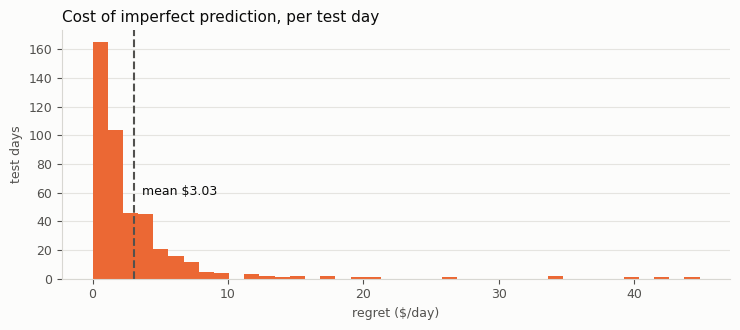

In [21]:
def plot_regret_hist(df, path=None):
    """Regret per test day - one series, so the title names it and no legend is needed."""
    fig, ax = plt.subplots(figsize=(7.5, 3.4), facecolor=SURFACE)
    _style(ax)
    ax.hist(df["regret"], bins=40, color=SER["pred"])
    ax.axvline(df["regret"].mean(), color=INK_MUTED, lw=1.5, ls="--")
    ax.annotate(f"mean ${df['regret'].mean():.2f}", (df["regret"].mean(), 0),
                xytext=(6, 60), textcoords="offset points", fontsize=9, color=INK)
    ax.set_xlabel("regret ($/day)", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("test days", fontsize=9, color=INK_MUTED)
    ax.set_title("Cost of imperfect prediction, per test day", fontsize=11, color=INK, loc="left")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


rows = [{"method": "no battery", "mean cost ($/day)": res["cost_nobat"].mean(),
         "mean regret ($/day)": np.nan, "captured": 0.0}]
for name, df in results.items():
    rows.append({"method": name, "mean cost ($/day)": df["cost_pred"].mean(),
                 "mean regret ($/day)": df["regret"].mean(), "captured": captured(df)})
rows.append({"method": "hindsight", "mean cost ($/day)": res["cost_hind"].mean(),
             "mean regret ($/day)": 0.0, "captured": 1.0})
summary22 = pd.DataFrame(rows).set_index("method")
print("B = %.1f MWh, %d test days" % (B_DEFAULT, len(res)))
print(summary22.round(3).to_string())
print("\nregret quantiles ($/day): %s | max %.2f"
      % (res["regret"].quantile([.5, .9, .99]).round(2).to_dict(), res["regret"].max()))

plot_regret_hist(res, VIS_DIR / "regret_hist.png")
plt.show()

### Step 8 - SAA sanity check on the mean-price argument

Sample $S$ price paths from the fitted distribution for a few days, solve
$\min_x \frac{1}{S}\sum_s p^{(s)\top} x$, and confirm the schedule matches the plug-in mean
solution. It should, since the sample mean of the draws converges to $\mathbb{E}[p]$ - this checks
the reasoning, it is not a better method.

In [22]:
def solve_saa(price_samples, d, B):
    """Solve the LP with the average of the sampled prices; equals the plug-in mean solution."""
    return solve_battery(np.asarray(price_samples).mean(axis=0), d, B)


rng = np.random.default_rng(SEED)
price_gaps, obj_gaps = [], []
for i in range(10):
    paths = sample_prices(mu_k[i], sigma2, 4000, rng)
    x_saa, _, _ = solve_saa(paths, D[i], B_DEFAULT)
    x_hat, _, _ = solve_battery(p_hat_k[i], D[i], B_DEFAULT)
    price_gaps.append(np.abs(paths.mean(axis=0) - p_hat_k[i]).max())
    # x_saa has to be near-optimal *for p_hat*, which is what the argument claims.
    # Comparing the schedules themselves is the wrong test: the LP has ties, so the
    # optimal vertex can jump under a cent of sampling noise at unchanged cost.
    obj_gaps.append(100 * (realised_cost(x_saa, p_hat_k[i])
                           / realised_cost(x_hat, p_hat_k[i]) - 1))

print("SAA (4000 draws/day) vs the plug-in mean solution, 10 test days:")
print("  max |sample mean - E[p]|     $%.4f/MWh" % max(price_gaps))
print("  max sub-optimality of x_saa  %.4f%% of the plug-in optimum" % max(obj_gaps))

SAA (4000 draws/day) vs the plug-in mean solution, 10 test days:
  max |sample mean - E[p]|     $0.2191/MWh
  max sub-optimality of x_saa  0.0392% of the plug-in optimum


### Step 9 - Sensitivity to battery capacity

Repeat Steps 4-7 over `B_VALUES`. Expect both curves to fall and flatten (as in Task 1.5), with the
gap between them - the price of imperfect prediction - widening as capacity gives the schedule more
freedom to act on wrong price signals.

   B  nobat   pred   hind  captured
 0.0 357.92 357.92 357.92       NaN
 2.0 357.92 315.40 312.96      0.95
 5.0 357.92 276.78 273.75      0.96
10.0 357.92 250.60 247.25      0.97
15.0 357.92 250.44 247.01      0.97


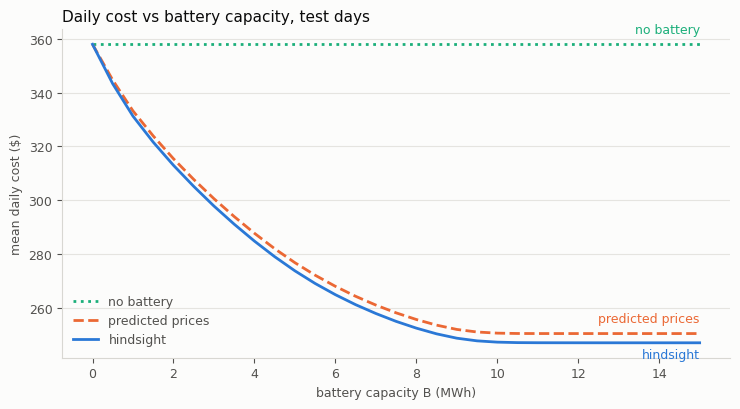

In [23]:
def plot_cost_vs_capacity(sweep, path=None):
    """Mean daily cost against capacity, for the three schedules."""
    fig, ax = plt.subplots(figsize=(7.5, 4.2), facecolor=SURFACE)
    _style(ax)
    ax.plot(sweep["B"], sweep["nobat"], color=SER["nobat"], lw=2, ls=":", label="no battery")
    ax.plot(sweep["B"], sweep["pred"], color=SER["pred"], lw=2, ls="--", label="predicted prices")
    ax.plot(sweep["B"], sweep["hind"], color=SER["hind"], lw=2, label="hindsight")
    # Direct labels as well as the legend - the aqua series is below 3:1 on this
    # surface, so it needs visible relief.
    for key, txt, dy in (("nobat", "no battery", 6), ("pred", "predicted prices", 6),
                         ("hind", "hindsight", -13)):
        ax.annotate(txt, (sweep["B"].iloc[-1], sweep[key].iloc[-1]), color=SER[key],
                    fontsize=9, ha="right", va="bottom", xytext=(0, dy),
                    textcoords="offset points")
    ax.set_xlabel("battery capacity B (MWh)", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("mean daily cost ($)", fontsize=9, color=INK_MUTED)
    ax.set_title("Daily cost vs battery capacity, test days", fontsize=11, color=INK, loc="left")
    ax.legend(frameon=False, fontsize=9, labelcolor=INK_MUTED, loc="lower left")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


sweep = pd.DataFrame([
    {"B": B, **{k: v for k, v in zip(
        ("nobat", "pred", "hind"),
        score_forecast(p_hat_k, p_true_k, D, B)[["cost_nobat", "cost_pred", "cost_hind"]].mean())},
     "captured": captured(score_forecast(p_hat_k, p_true_k, D, B))}
    for B in B_VALUES
])
print(sweep[sweep["B"].isin([0, 2, 5, 10, 15])].round(2).to_string(index=False))

plot_cost_vs_capacity(sweep, VIS_DIR / "cost_vs_capacity_pred_vs_hindsight.png")
plt.show()

### Step 10 - Diagnostic plot for one day

For a representative test day, plot realised vs predicted prices on one axis and $\hat{x}$ vs
$x^\star$ on another. This shows the mechanism directly: what matters is the predicted *ordering*
of cheap and expensive hours, not the price level.

worst regret day: 2016-06-26  ($44.83)


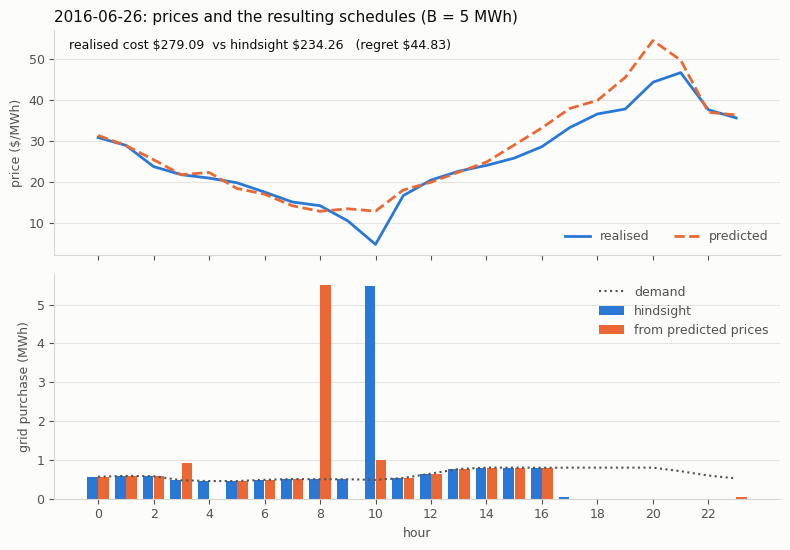

In [24]:
def plot_sample_day(i, p_hat, p_true, D, dates, B, path=None):
    """Top: realised vs predicted prices. Bottom: the two schedules they produce."""
    r = solve_day(p_hat[i], p_true[i], D[i], B)
    hours = np.arange(T)
    fig, axes = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True, facecolor=SURFACE)

    ax = axes[0]
    _style(ax)
    ax.plot(hours, p_true[i], color=SER["hind"], lw=2, label="realised")
    ax.plot(hours, p_hat[i], color=SER["pred"], lw=2, ls="--", label="predicted")
    ax.set_ylabel("price ($/MWh)", fontsize=9, color=INK_MUTED)
    ax.annotate(f"realised cost ${r['cost_pred']:.2f}  vs hindsight ${r['cost_hind']:.2f}"
                f"   (regret ${r['cost_pred'] - r['cost_hind']:.2f})",
                (0.02, 0.96), xycoords="axes fraction", va="top", fontsize=9, color=INK)
    ax.set_title(f"{dates[i]}: prices and the resulting schedules (B = {B:g} MWh)",
                 fontsize=11, color=INK, loc="left")
    ax.legend(frameon=False, fontsize=9, labelcolor=INK_MUTED, ncol=2, loc="lower right")

    ax = axes[1]
    _style(ax)
    ax.bar(hours - 0.2, r["x_star"], width=0.38, color=SER["hind"], label="hindsight")
    ax.bar(hours + 0.2, r["x_hat"], width=0.38, color=SER["pred"], label="from predicted prices")
    ax.plot(hours, D[i], color=INK_MUTED, lw=1.5, ls=":", label="demand")
    ax.set_xlabel("hour", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("grid purchase (MWh)", fontsize=9, color=INK_MUTED)
    ax.set_xticks(range(0, 24, 2))
    ax.legend(frameon=False, fontsize=9, labelcolor=INK_MUTED, loc="upper right")

    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


worst = int(res["regret"].idxmax())
print("worst regret day: %s  ($%.2f)" % (dates_k[worst], res["regret"].max()))
plot_sample_day(worst, p_hat_k, p_true_k, D, dates_k, B_DEFAULT,
                VIS_DIR / "schedule_sample_day.png")
plt.show()

---
# 4.1 Analysis

1. per-day regret $R_i = C^{NN}_i - C^{\text{off}}_i$: mean, P90, P95, max, and how concentrated it is;
2. the worst days: predicted vs true prices, purchases, and battery level;
3. prediction error vs regret: does a lower daily RMSE mean a lower regret?
4. whether the tail clusters in particular months.

Only the shape term can cause regret. Everything below is at $B = $ `B_DEFAULT` = 5 MWh.

### Step 1 - Per-day diagnostics and regret distribution

In [25]:
from scipy.stats import spearmanr, pearsonr


def day_diagnostics(p_fore, p_true, D, B, dates) -> pd.DataFrame:
    """One row per day: regret, schedule details, and the prediction-error measures."""
    rows = []
    for i in range(len(p_true)):
        x_hat, s_hat, _ = solve_battery(p_fore[i], D[i], B)
        x_star, s_star, _ = solve_battery(p_true[i], D[i], B)
        cost_pred, cost_hind = realised_cost(x_hat, p_true[i]), realised_cost(x_star, p_true[i])
        cost_nobat = realised_cost(D[i], p_true[i])

        err = p_fore[i] - p_true[i]
        bias = err.mean()
        rows.append({
            "date": dates[i],
            "regret": cost_pred - cost_hind,
            "saving_hind": cost_nobat - cost_hind,              # what a perfect forecast would save
            "lost_share": (cost_pred - cost_hind) / max(cost_nobat - cost_hind, 1e-9),
            "rmse": np.sqrt((err ** 2).mean()),                 # $/MWh
            "bias": bias,                                       # level error, $/MWh
            "shape_rmse": np.sqrt(((err - bias) ** 2).mean()),  # shape error, $/MWh
            "rank_corr": spearmanr(p_fore[i], p_true[i])[0],    # does it order the hours right?
            # realised price at the hour the forecast thinks is cheapest, minus the true minimum
            "trough_miss": p_true[i][np.argmin(p_fore[i])] - p_true[i].min(),
            "hour_true_min": int(p_true[i].argmin()),
            "hour_pred_min": int(p_fore[i].argmin()),
            "true_peak": p_true[i].max(),
            "true_spread": p_true[i].max() - p_true[i].min(),
            "hour_true_peak": int(p_true[i].argmax()),
            "hour_pred_peak": int(p_fore[i].argmax()),
            "x_l1_diff": np.abs(x_hat - x_star).sum(),          # MWh bought at a different time
            "x_hat": x_hat, "x_star": x_star, "s_hat": s_hat, "s_star": s_star,
        })
    return pd.DataFrame(rows)


diag = day_diagnostics(p_hat_k, p_true_k, D, B_DEFAULT, dates_k)
assert np.allclose(diag["regret"], res["regret"], atol=1e-4)   # same numbers as Step 5 of 2.2


def regret_stats(regret: pd.Series) -> dict:
    """Mean / quantiles / max, plus how much of the total regret the worst days account for."""
    r = regret.clip(lower=0).sort_values(ascending=False)
    n = len(r)
    return {
        "mean": r.mean(), "P50": r.quantile(.5), "P90": r.quantile(.9),
        "P95": r.quantile(.95), "P99": r.quantile(.99), "max": r.max(),
        "worst 5% share": r.iloc[: int(np.ceil(.05 * n))].sum() / r.sum(),
        "worst 10% share": r.iloc[: int(np.ceil(.10 * n))].sum() / r.sum(),
    }


# PriceNet against the baselines scored in Step 6 of 2.2, same B and days.
regret_table = pd.DataFrame({name: regret_stats(df["regret"]) for name, df in results.items()}).T
print("Regret per test day ($/day), B = %.1f MWh, %d days" % (B_DEFAULT, len(diag)))
print(regret_table.round(3).to_string())


Regret per test day ($/day), B = 5.0 MWh, 436 days
               mean    P50     P90     P95     P99     max  worst 5% share  worst 10% share
PriceNet      3.030  1.630   6.288   8.956  31.477  44.825           0.331            0.451
persistence   4.290  1.352  11.234  18.591  36.253  98.029           0.385            0.561
hour_mean    12.532  8.085  28.953  40.959  73.772  88.224           0.230            0.363


### Step 2 - The worst days

In [26]:
N_WORST = 10
worst_idx = diag["regret"].sort_values(ascending=False).index[:N_WORST]

cols = ["date", "regret", "saving_hind", "lost_share", "rmse", "bias", "shape_rmse",
        "rank_corr", "trough_miss", "hour_true_min", "hour_pred_min", "true_spread", "x_l1_diff"]
typical = diag[cols[1:]].median(numeric_only=True).rename("median day")

print("Worst %d days by regret (B = %.1f MWh)" % (N_WORST, B_DEFAULT))
print(diag.loc[worst_idx, cols].round(2).to_string(index=False))
print("\nMedian test day for comparison:")
print(typical.round(2).to_string())


Worst 10 days by regret (B = 5.0 MWh)
      date  regret  saving_hind  lost_share  rmse  bias  shape_rmse  rank_corr  trough_miss  hour_true_min  hour_pred_min  true_spread  x_l1_diff
2016-06-26   44.83       170.99        0.26  3.68  2.03        3.07       0.99         9.45             10              8        41.91      10.97
2016-01-26   41.62        46.91        0.89  7.88  6.89        3.83       0.77         8.09              7              4        23.46      12.77
2016-12-19   39.68       175.11        0.23 10.88 -9.11        5.94       0.90         2.64              4              6        41.94      20.78
2016-02-15   34.40        64.13        0.54  9.39  6.98        6.29       0.71         2.64              9             20        29.77      13.23
2016-06-19   34.21       164.68        0.21  6.86  4.89        4.81       0.99         7.13             10              8        41.74      11.76
2016-02-14   26.41        57.69        0.46 16.68 13.37        9.98       0.68        

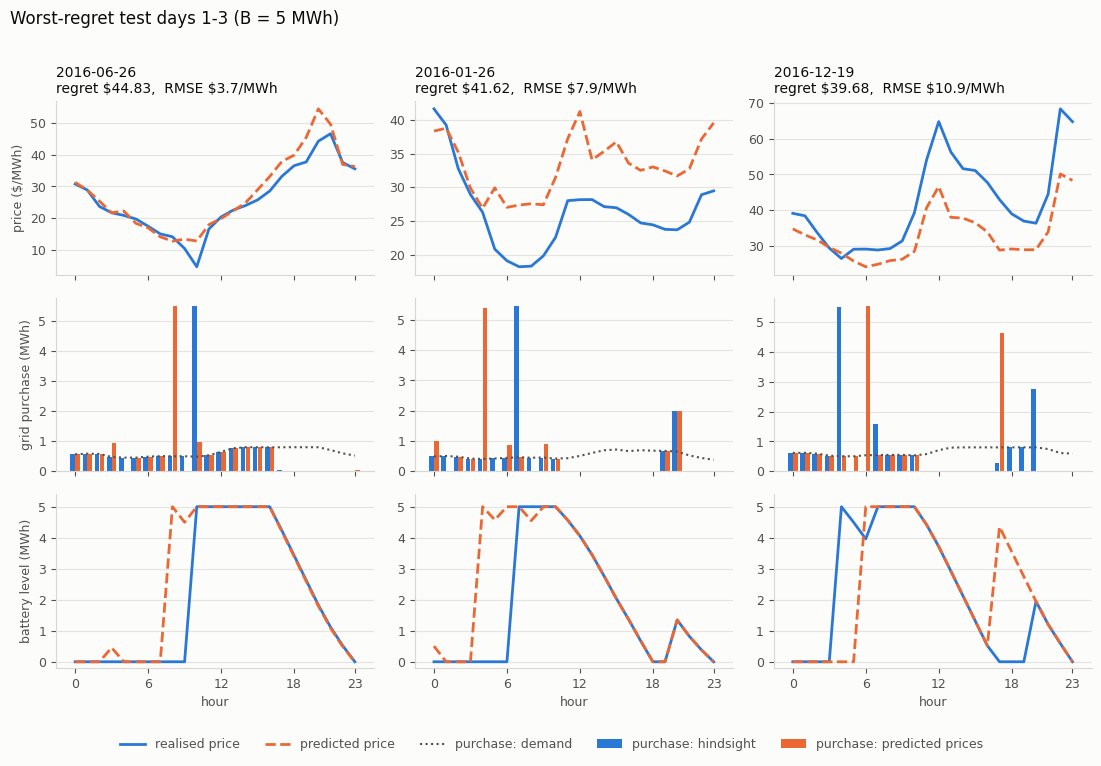

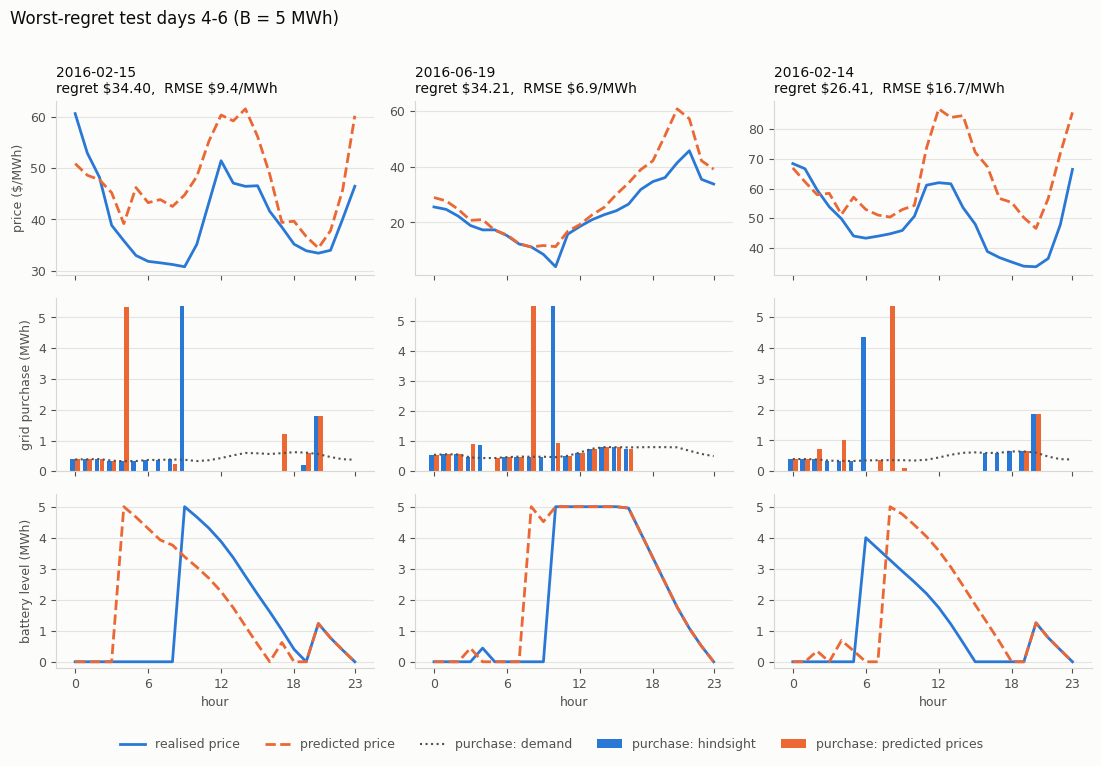

In [27]:
def plot_worst_days(idx, diag, p_fore, p_true, D, B, title, path=None):
    """One column per day. Rows: prices, grid purchases, battery level (predicted vs hindsight)."""
    n = len(idx)
    hours = np.arange(T)
    fig, axes = plt.subplots(3, n, figsize=(3.7 * n, 7.6), sharex=True, facecolor=SURFACE)
    axes = axes.reshape(3, n)

    for c, i in enumerate(idx):
        r = diag.loc[i]
        ax = axes[0, c]; _style(ax)
        ax.plot(hours, p_true[i], color=SER["hind"], lw=2, label="realised price")
        ax.plot(hours, p_fore[i], color=SER["pred"], lw=2, ls="--", label="predicted price")
        ax.set_title(f"{r['date']}\nregret \\${r['regret']:.2f},  RMSE \\${r['rmse']:.1f}/MWh",
                     fontsize=10, color=INK, loc="left")

        ax = axes[1, c]; _style(ax)
        ax.bar(hours - 0.2, r["x_star"], width=0.38, color=SER["hind"], label="hindsight")
        ax.bar(hours + 0.2, r["x_hat"], width=0.38, color=SER["pred"], label="predicted prices")
        ax.plot(hours, D[i], color=INK_MUTED, lw=1.5, ls=":", label="demand")

        ax = axes[2, c]; _style(ax)
        ax.plot(hours, r["s_star"], color=SER["hind"], lw=2, label="hindsight")
        ax.plot(hours, r["s_hat"], color=SER["pred"], lw=2, ls="--", label="predicted prices")
        ax.set_ylim(-0.2, B + 0.4)
        ax.set_xlabel("hour", fontsize=9, color=INK_MUTED)
        ax.set_xticks([0, 6, 12, 18, 23])

    for row, lab in enumerate(["price (\\$/MWh)", "grid purchase (MWh)", "battery level (MWh)"]):
        axes[row, 0].set_ylabel(lab, fontsize=9, color=INK_MUTED)
    # one shared legend below the grid, so no panel's data is covered
    h1, l1 = axes[0, 0].get_legend_handles_labels()
    h2, l2 = axes[1, 0].get_legend_handles_labels()
    fig.legend(h1 + h2, l1 + [f"purchase: {l}" for l in l2], loc="lower center", ncol=5,
               frameon=False, fontsize=9, labelcolor=INK_MUTED, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(title, fontsize=12, color=INK, x=0.012, ha="left")
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


plot_worst_days(worst_idx[:3], diag, p_hat_k, p_true_k, D, B_DEFAULT,
                f"Worst-regret test days 1-3 (B = {B_DEFAULT:g} MWh)",
                VIS_DIR / "worst_days_1_3.png")
plot_worst_days(worst_idx[3:6], diag, p_hat_k, p_true_k, D, B_DEFAULT,
                f"Worst-regret test days 4-6 (B = {B_DEFAULT:g} MWh)",
                VIS_DIR / "worst_days_4_6.png")
plt.show()


In [28]:
def hourly_regret(diag, p_true, idx):
    """Mean over days in idx of p_t * (x_hat_t - x_star_t), shape (24,)."""
    return np.mean([p_true[i] * (diag.loc[i, "x_hat"] - diag.loc[i, "x_star"]) for i in idx], axis=0)


contrib = pd.DataFrame({
    "worst 10 days": hourly_regret(diag, p_true_k, worst_idx),
    "all days": hourly_regret(diag, p_true_k, diag.index),
}, index=pd.RangeIndex(T, name="hour"))
print("Per-hour contribution to regret, $/day (sums to mean regret of the group):")
print(contrib.round(2).T.to_string())
print("sums:", contrib.sum().round(2).to_dict())


Per-hour contribution to regret, $/day (sums to mean regret of the group):
hour             0     1     2      3     4     5      6      7      8      9     10     11    12    13    14    15    16     17     18     19    20    21    22    23
worst 10 days  2.10 -0.09  0.47  14.85  5.39 -2.31 -10.31 -15.28  42.34 -16.62 -8.14  14.49 -1.86  0.00  0.00 -0.00 -3.70  27.40  -8.14  -3.12 -9.99 -0.00 -0.00  2.08
all days       0.09  0.13 -0.13   1.68 -0.80  0.32  -5.43   6.48  -2.90  -0.23  1.43  -0.90  0.76 -0.87  0.37 -0.01 -0.52   3.18  12.75 -14.34  1.36  0.62 -0.13  0.11
sums: {'worst 10 days': 29.58, 'all days': 3.03}


### Step 3 - Prediction accuracy vs decision quality

Correlation of each per-day quantity with regret:
             Spearman  Pearson
rmse            0.124    0.257
bias            0.010    0.117
shape_rmse      0.216    0.219
rank_corr      -0.166   -0.296
trough_miss     0.608    0.795
true_spread     0.123    0.100
true_peak       0.175    0.115
saving_hind     0.047    0.083

Regret by daily-RMSE quintile ($/day):
            count  mean  median    max
rmse_q                                
Q1 (best)      88  2.20    1.21   8.81
Q2             87  2.53    1.66  17.48
Q3             87  2.39    1.40  20.70
Q4             87  2.98    1.73  44.83
Q5 (worst)     87  5.06    1.96  41.62


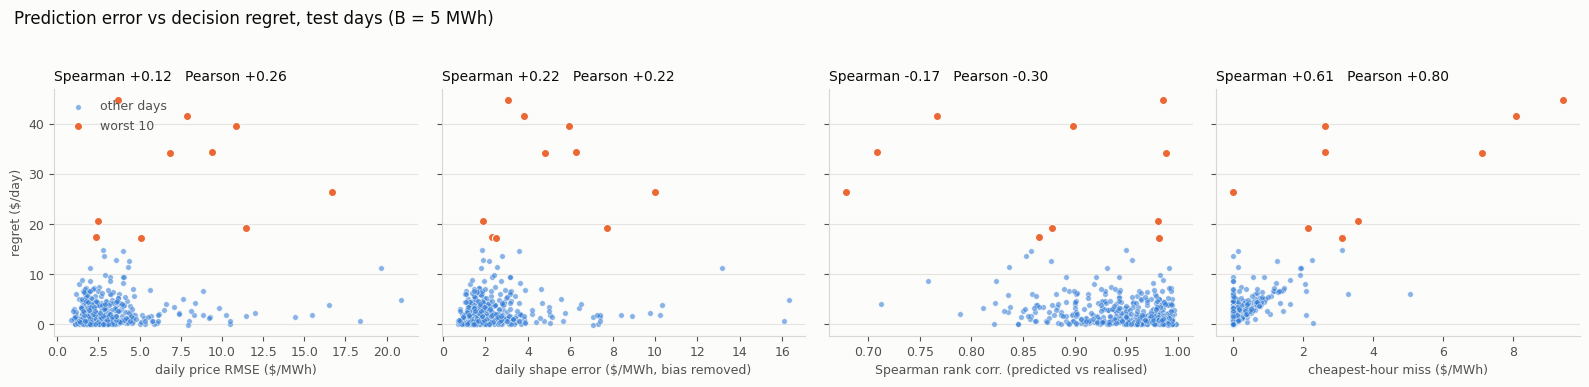

In [29]:
def plot_error_vs_regret(diag, worst_idx, path=None):
    """Regret against three per-day error measures; the worst days are highlighted."""
    specs = [("rmse", "daily price RMSE (\\$/MWh)"),
             ("shape_rmse", "daily shape error (\\$/MWh, bias removed)"),
             ("rank_corr", "Spearman rank corr. (predicted vs realised)"),
             ("trough_miss", "cheapest-hour miss (\\$/MWh)")]
    other = diag.index.difference(worst_idx)
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharey=True, facecolor=SURFACE)
    for ax, (col, lab) in zip(axes, specs):
        _style(ax)
        ax.scatter(diag.loc[other, col], diag.loc[other, "regret"], s=16, alpha=0.55,
                   color=SER["hind"], edgecolor=SURFACE, linewidth=0.5, label="other days")
        ax.scatter(diag.loc[worst_idx, col], diag.loc[worst_idx, "regret"], s=34,
                   color=SER["pred"], edgecolor=SURFACE, linewidth=0.8,
                   label=f"worst {len(worst_idx)}")
        rho = spearmanr(diag[col], diag["regret"])[0]
        r = pearsonr(diag[col], diag["regret"])[0]
        ax.set_title(f"Spearman {rho:+.2f}   Pearson {r:+.2f}", fontsize=10, color=INK, loc="left")
        ax.set_xlabel(lab, fontsize=9, color=INK_MUTED)
    axes[0].set_ylabel("regret ($/day)", fontsize=9, color=INK_MUTED)
    axes[0].legend(frameon=False, fontsize=9, labelcolor=INK_MUTED, loc="upper left")
    fig.suptitle(f"Prediction error vs decision regret, test days (B = {B_DEFAULT:g} MWh)",
                 fontsize=12, color=INK, x=0.012, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


corr_cols = ["rmse", "bias", "shape_rmse", "rank_corr", "trough_miss",
             "true_spread", "true_peak", "saving_hind"]
corr = pd.DataFrame({
    "Spearman": [spearmanr(diag[c], diag["regret"])[0] for c in corr_cols],
    "Pearson": [pearsonr(diag[c], diag["regret"])[0] for c in corr_cols],
}, index=corr_cols)
print("Correlation of each per-day quantity with regret:")
print(corr.round(3).to_string())

# If RMSE decided regret, the lowest-RMSE days would all be low-regret. Check by quintile.
diag["rmse_q"] = pd.qcut(diag["rmse"], 5, labels=["Q1 (best)", "Q2", "Q3", "Q4", "Q5 (worst)"])
print("\nRegret by daily-RMSE quintile ($/day):")
print(diag.groupby("rmse_q", observed=True)["regret"]
          .agg(["count", "mean", "median", "max"]).round(2).to_string())

plot_error_vs_regret(diag, worst_idx, VIS_DIR / "rmse_vs_regret.png")
plt.show()


In [30]:
diag["month"] = pd.to_datetime(diag["date"]).dt.month
by_month = diag.groupby("month").agg(
    days=("regret", "size"), mean_regret=("regret", "mean"), P90=("regret", lambda r: r.quantile(.9)),
    max_regret=("regret", "max"), mean_rmse=("rmse", "mean"), mean_spread=("true_spread", "mean"))
print(by_month.round(2).to_string())
print("\nMonths of the worst %d days:" % N_WORST, sorted(diag.loc[worst_idx, "month"].tolist()))


       days  mean_regret    P90  max_regret  mean_rmse  mean_spread
month                                                              
1        31         6.46  12.79       41.62       3.70        23.08
2        28         3.82   5.71       34.40       3.94        18.45
3        31         2.08   4.70        6.47       2.62        18.80
4        30         1.91   3.91        8.64       2.83        21.22
5        31         1.69   3.97        9.55       2.11        19.45
6        30         5.95  15.39       44.83       3.01        29.85
7        31         2.75   5.28       17.29       5.75        41.99
8        31         2.16   4.46       11.23       4.76        39.00
9        30         1.79   4.17        9.93       3.68        35.59
10       41         2.24   4.77       13.59       2.44        21.24
11       60         2.23   4.53        9.39       2.69        21.04
12       62         3.71   7.06       39.68       3.12        22.10

Months of the worst 10 days: [1, 1, 1, 2, 2, 6,

---
# Sub-task 3.1: Battery optimization layer

Task 3 trains the price model on the *decision* it leads to. That needs the gradient of the LP
solution with respect to the predicted prices, and an LP gives none: its solution jumps between
vertices, so it is piecewise constant in $\hat p$. Adding a strongly convex term makes the solution
unique and smooth, and `cvxpylayers` can then differentiate it:

$$
\min_x \; \sum_{t=0}^{23} p_t x_t + \frac{\epsilon}{2}\lVert x\rVert_2^2
\quad\text{s.t.}\quad s_0 = x_0 - d_0,\;\; s_t = s_{t-1} + x_t - d_t,\;\; 0 \le s_t \le B,\;\; x_t \ge 0.
$$

This is the Task 2 LP plus the $\frac{\epsilon}{2}\lVert x\rVert_2^2$ term, with $p$, $d$ and $B$ as
parameters. All tensors passed to the layer must share one dtype; the numpy data is float64, so
everything is `torch.float64`.

In [31]:
from cvxpylayers.torch import CvxpyLayer

F64 = torch.float64
SOLVER_ARGS = {"eps": 1e-9}     # SCS tolerance for the layer (the default 1e-4 is too loose to compare with cvxpy)


def build_regularised_battery(T=T, eps=1e-3):
    x, s = cp.Variable(T, nonneg=True), cp.Variable(T, nonneg=True)
    p, d, B = cp.Parameter(T), cp.Parameter(T, nonneg=True), cp.Parameter(nonneg=True)
    cons = [s[0] == x[0] - d[0], s <= B]
    cons += [s[t] == s[t - 1] + x[t] - d[t] for t in range(1, T)]
    prob = cp.Problem(cp.Minimize(p @ x + (eps / 2) * cp.sum_squares(x)), cons)
    assert prob.is_dpp(), "cvxpylayers needs a DPP-compliant problem"
    return {"prob": prob, "x": x, "s": s, "p": p, "d": d, "B": B}


def make_battery_layer(eps):
    m = build_regularised_battery(eps=eps)
    layer = CvxpyLayer(m["prob"], parameters=[m["p"], m["d"], m["B"]], variables=[m["x"], m["s"]])
    return layer, m


def layer_solve(layer, p, d, B):
    """Run the layer on numpy inputs and return (x, s) as numpy arrays (no gradients)."""
    with torch.no_grad():
        x, s = layer(torch.tensor(p, dtype=F64), torch.tensor(d, dtype=F64),
                     torch.tensor(float(B), dtype=F64), solver_args=SOLVER_ARGS)
    return x.numpy(), s.numpy()


def cvxpy_solve(m, p, d, B):
    m["p"].value, m["d"].value, m["B"].value = np.asarray(p, float), np.asarray(d, float), float(B)
    m["prob"].solve(solver=cp.CLARABEL)
    return m["x"].value.copy(), m["s"].value.copy()

### Step 1 - cvxpylayers against cvxpy

In [32]:
def reg_objective(p, x, eps):
    return float(np.asarray(p) @ x + eps / 2 * (x @ x))


rows = []
for eps in [1.0, 1e-1, 1e-2, 1e-3]:
    layer, m = make_battery_layer(eps)
    dx, dobj = [], []
    for i in range(len(p_hat_k)):
        x_layer, _ = layer_solve(layer, p_hat_k[i], D[i], B_DEFAULT)
        x_cvx, _ = cvxpy_solve(m, p_hat_k[i], D[i], B_DEFAULT)
        dx.append(np.abs(x_layer - x_cvx).max())
        dobj.append(abs(reg_objective(p_hat_k[i], x_layer, eps) - reg_objective(p_hat_k[i], x_cvx, eps)))
    rows.append({"eps": eps, "max |x_layer - x_cvxpy| (MWh)": max(dx), "max |objective diff| ($)": max(dobj)})

print("%d test days, B = %.1f MWh" % (len(p_hat_k), B_DEFAULT))
print(pd.DataFrame(rows).set_index("eps").to_string(float_format=lambda v: "%.2e" % v))

436 test days, B = 5.0 MWh
       max |x_layer - x_cvxpy| (MWh)  max |objective diff| ($)
eps                                                           
1.000                       5.94e-04                  2.17e-06
0.100                       1.55e-03                  1.79e-06
0.010                       7.25e-03                  1.65e-06
0.001                       2.39e-03                  1.83e-06


### Step 2 - Regularised problem against the original LP


In [33]:
EPS_GRID = [1.0, 1e-1, 1e-2, 1e-3, 1e-4]
n_days = len(p_hat_k)

x_lp = [solve_battery(p_hat_k[i], D[i], B_DEFAULT)[0] for i in range(n_days)]
cost_lp = np.array([realised_cost(x_lp[i], p_true_k[i]) for i in range(n_days)])
hind_lp = np.array([solve_battery(p_true_k[i], D[i], B_DEFAULT)[2] for i in range(n_days)])

rows = []
for eps in EPS_GRID:
    lay, _ = make_battery_layer(eps)
    x_reg = [layer_solve(lay, p_hat_k[i], D[i], B_DEFAULT)[0] for i in range(n_days)]
    cost_reg = np.array([realised_cost(x_reg[i], p_true_k[i]) for i in range(n_days)])
    hind_reg = np.array([realised_cost(layer_solve(lay, p_true_k[i], D[i], B_DEFAULT)[0], p_true_k[i])
                         for i in range(n_days)])
    rows.append({
        "eps": eps,
        "max |x - x_LP| (MWh)": max(np.abs(x_reg[i] - x_lp[i]).max() for i in range(n_days)),
        "cost at p_hat, mean ($/day)": cost_reg.mean(),
        "gap to LP ($/day)": (cost_reg - cost_lp).mean(),
        "gap to LP (%)": 100 * (cost_reg.mean() / cost_lp.mean() - 1),
        "hindsight gap to LP (%)": 100 * (hind_reg.mean() / hind_lp.mean() - 1),
    })

eps_table = pd.DataFrame(rows).set_index("eps")
print("LP: mean realised cost at p_hat $%.3f/day, hindsight $%.3f/day (B = %.1f MWh, %d days)"
      % (cost_lp.mean(), hind_lp.mean(), B_DEFAULT, n_days))
print(eps_table.round(4).to_string())

c:\Users\johnb\Downloads\Honours\.venv\lib\site-packages\diffcp\cone_program.py:442: UserWarning: Solved/Inaccurate.
  warnings.warn("Solved/Inaccurate.")


LP: mean realised cost at p_hat $276.778/day, hindsight $273.748/day (B = 5.0 MWh, 436 days)
        max |x - x_LP| (MWh)  cost at p_hat, mean ($/day)  gap to LP ($/day)  gap to LP (%)  hindsight gap to LP (%)
eps                                                                                                                 
1.0000                3.9322                     277.9227             1.1449         0.4137                   0.8145
0.1000                2.9392                     276.6311            -0.1467        -0.0530                   0.0641
0.0100                2.2764                     276.7728            -0.0050        -0.0018                   0.0012
0.0010                2.1539                     276.7845             0.0067         0.0024                  -0.0000
0.0001                0.9103                     276.7801             0.0023         0.0008                  -0.0000


### Step 3 - Gradients through the layer



In [34]:
EPS_GRAD, H = 1.0, 1e-3          # regularisation for the check, finite-difference step ($/MWh)
N_COMP = 6                        # components compared on the main day


def make_loss(layer, p_true, d, B):
    """L(p_hat) = p_true . x*(p_hat), differentiable in p_hat."""
    p_true_t, d_t, B_t = (torch.tensor(a, dtype=F64) for a in (p_true, d, float(B)))
    def loss(p_hat_t):
        x, _ = layer(p_hat_t, d_t, B_t, solver_args=SOLVER_ARGS)
        return (p_true_t * x).sum()
    return loss


def autograd_grad(loss, p_hat):
    p_t = torch.tensor(p_hat, dtype=F64, requires_grad=True)
    value = loss(p_t)
    value.backward()
    return value.item(), p_t.grad.numpy()


def finite_diff(loss, p_hat, k, h=H):
    """Central difference of L in component k of p_hat."""
    e = np.zeros_like(p_hat)
    e[k] = h
    with torch.no_grad():
        return ((loss(torch.tensor(p_hat + e, dtype=F64)) - loss(torch.tensor(p_hat - e, dtype=F64))) / (2 * h)).item()


layer_g, _ = make_battery_layer(EPS_GRAD)

# main day: the worst day of 4.1
i = int(worst_idx[0])
loss = make_loss(layer_g, p_true_k[i], D[i], B_DEFAULT)
value, g_ad = autograd_grad(loss, p_hat_k[i])
comps = np.argsort(-np.abs(g_ad))[:N_COMP]
g_fd = np.array([finite_diff(loss, p_hat_k[i], k) for k in comps])

print("%s (worst regret day), eps = %g, h = %g, L = %.4f" % (dates_k[i], EPS_GRAD, H, value))
print(pd.DataFrame({"hour": comps, "autograd": g_ad[comps], "finite diff": g_fd,
                    "abs diff": np.abs(g_ad[comps] - g_fd)}).round(5).to_string(index=False))

# the same comparison on other days, largest components only
errs = []
for j in np.linspace(0, n_days - 1, 8).astype(int):
    lj = make_loss(layer_g, p_true_k[j], D[j], B_DEFAULT)
    _, gj = autograd_grad(lj, p_hat_k[j])
    top = np.argsort(-np.abs(gj))[:3]
    errs += [abs(gj[k] - finite_diff(lj, p_hat_k[j], k)) / max(abs(gj[k]), 1e-12) for k in top]
print("\n8 other days, 3 largest components each: max relative error %.1e" % max(errs))

# how the gradient depends on eps: largest |dL/dp_hat| per day, over 40 days spread across the test split
rows = []
for eps in [1e1, 1.0, 1e-1, 1e-2, 1e-3]:
    lay, _ = make_battery_layer(eps)
    biggest = np.array([
        np.abs(autograd_grad(make_loss(lay, p_true_k[j], D[j], B_DEFAULT), p_hat_k[j])[1]).max()
        for j in np.linspace(0, n_days - 1, 40).astype(int)])
    rows.append({"eps": eps, "median": np.median(biggest), "90th pct": np.quantile(biggest, 0.9),
                 "max": biggest.max(), "share of days with gradient < 0.01": (biggest < 0.01).mean()})
print("\nLargest |dL/dp_hat| per day (40 days):")
print(pd.DataFrame(rows).set_index("eps").round(4).to_string())

2016-06-26 (worst regret day), eps = 1, h = 0.001, L = 261.6748
 hour  autograd  finite diff  abs diff
   10   6.38514      6.38504   0.00010
    7  -3.96505     -3.96497   0.00008
    8  -3.06503     -3.06493   0.00010
    9   0.64498      0.64507   0.00009
    3  -0.41512     -0.41500   0.00012
    4   0.41495      0.41499   0.00004

8 other days, 3 largest components each: max relative error 8.0e-04

Largest |dL/dp_hat| per day (40 days):
        median  90th pct        max  share of days with gradient < 0.01
eps                                                                    
10.000  0.4741    0.7211     1.8356                               0.000
1.000   1.2198    2.3540     4.1627                               0.000
0.100   2.5001   12.1398    42.1654                               0.200
0.010   0.0002    0.7998    53.4985                               0.900
0.001   0.0002    0.0004  1165.1274                               0.975


### Task 3.2: Decision-Focused Learning

This step trains the neural network by accounting for the cost of the optimization decisions it produces.

In the conventional learn-to-optimize (LTO) approach, the neural network is trained to minimize the mean squared error between the predicted and actual prices:

$$
L_{\mathrm{LTO}}(\theta)
=
\frac{1}{N}\sum_{i\in[N]}
\left\|f_\theta(\mathbf{z}_i)-\mathbf{p}_i\right\|_2^2.
$$

In decision-focused learning (DFL), instead of directly minimizing prediction error, the neural network is trained to minimize the cost associated with the resulting optimization decisions. For each sample $i$, the network predicts the prices $\hat{\mathbf{p}}_i=f_\theta(\mathbf{z}_i)$, which are used to solve the regularized optimization problem~\eqref{p:regularized}, yielding the optimal decision $\mathbf{x}_i^*(\theta)$.

The decision loss is then evaluated using the actual realized prices $\mathbf{p}_i$:

$$
L_{\mathrm{DFL}}(\theta)
=
\frac{1}{N}\sum_{i\in[N]}
\mathbf{p}_i^\top\mathbf{x}_i^*(\theta).
$$

To train the neural network, we compute

In [35]:
def dfl_loader(split, shuffle, batch_size=64):
    """Load the data for the differentiable forecast loss, with a PyTorch DataLoader."""
    D_s, keep_s = attach_demand(split["dates"], demand_profiles)
    ds = TensorDataset(torch.tensor(split["Z"][keep_s], dtype=torch.float32),
                       torch.tensor(split["prices"][keep_s], dtype=torch.float64),
                       torch.tensor(D_s, dtype=torch.float64))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle)


def lp_cost(model, split, B=B_DEFAULT):
    D_s, keep_s = attach_demand(split["dates"], demand_profiles)
    p_hat = expected_price(predict(model, split["Z"][keep_s]), sigma2)
    return score_forecast(p_hat, split["prices"][keep_s], D_s, B)["cost_pred"].mean()

def train_dfl(model, eps=0.1, lr=1e-5, max_epochs=30, patience=5, B=B_DEFAULT):
    """Train the model to minimise the realised cost of the battery schedule under its forecast.

    The loss is differentiable in the forecast, so we can backpropagate through the LP.
    """
    layer, _ = make_battery_layer(eps)
    s2, B_t = torch.tensor(sigma2, dtype=F64), torch.tensor(float(B), dtype=F64)
    train_loader = dfl_loader(splits["train"], shuffle=True)
    opt = optim.Adam(model.parameters(), lr=lr)
    best_valuation, best_epoch = lp_cost(model, splits["val"], B), -1
    best_state = copy.deepcopy(model.state_dict())
    print(f"start      val LP cost {best_valuation:.3f}  (MSE-trained model, before DFL)")
    for epoch in range(max_epochs):
        model.train()
        for Z_batch, P_batch, D_batch in train_loader:
            opt.zero_grad()
            P_hat_batch = torch.exp(model(Z_batch).double() + s2 / 2)  # log-normal mean
            x_batch, _ = layer(P_hat_batch, D_batch, B_t.expand(Z_batch.size(0)), solver_args={"eps": 1e-6})
            loss = (P_batch * x_batch).sum(dim=1).mean()  # mean realised cost over the batch
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

        # once per epoch, after all batches
        val = lp_cost(model, splits["val"], B)
        print(f"epoch {epoch:3d}  train loss {loss.item():.3f}  val LP cost {val:.3f}")
        if val < best_valuation:
            best_valuation, best_epoch = val, epoch
            best_state = copy.deepcopy(model.state_dict())
        if epoch - best_epoch >= patience:
            print(f"early stopping at epoch {epoch}, best val LP cost {best_valuation:.3f}")
            break

    model.load_state_dict(best_state)
    return model


model_dfl = train_dfl(copy.deepcopy(model), eps=0.1, lr=1e-5, max_epochs=30, patience=5, B=B_DEFAULT)


start      val LP cost 295.552  (MSE-trained model, before DFL)
epoch   0  train loss 408.221  val LP cost 295.555
epoch   1  train loss 393.718  val LP cost 295.981
epoch   2  train loss 393.234  val LP cost 295.937
epoch   3  train loss 399.327  val LP cost 295.439
epoch   4  train loss 402.642  val LP cost 295.401
epoch   5  train loss 380.109  val LP cost 295.359
epoch   6  train loss 389.800  val LP cost 295.280
epoch   7  train loss 439.703  val LP cost 295.257
epoch   8  train loss 410.801  val LP cost 295.232
epoch   9  train loss 450.086  val LP cost 295.270
epoch  10  train loss 419.059  val LP cost 295.395
epoch  11  train loss 401.630  val LP cost 295.747
epoch  12  train loss 383.821  val LP cost 295.800
epoch  13  train loss 416.074  val LP cost 295.912
early stopping at epoch 13, best val LP cost 295.232


### DFL against the MSE-trained model and hindsight

In [36]:
# DFL forecasts on the test days, converted and aligned exactly as the MSE ones were
# (2.1 Step 9, 2.2 Step 3), then scored with the true LP as in 2.2 Steps 4-7.
mu_dfl_k = predict(model_dfl, splits["test"]["Z"])[keep]
p_hat_dfl_k = expected_price(mu_dfl_k, sigma2)

res_dfl = score_forecast(p_hat_dfl_k, p_true_k, D, B_DEFAULT, dates_k)
assert (res_dfl["regret"] >= -1e-5).all(), res_dfl["regret"].min()

rows = [{"method": "no battery", "mean cost ($/day)": res["cost_nobat"].mean(),
         "mean regret ($/day)": np.nan, "captured": 0.0}]
for name, df in (("MSE (Task 2)", res), ("DFL", res_dfl)):
    rows.append({"method": name, "mean cost ($/day)": df["cost_pred"].mean(),
                 "mean regret ($/day)": df["regret"].mean(), "captured": captured(df)})
rows.append({"method": "hindsight", "mean cost ($/day)": res["cost_hind"].mean(),
             "mean regret ($/day)": 0.0, "captured": 1.0})
summary32 = pd.DataFrame(rows).set_index("method")
print("B = %.1f MWh, %d test days" % (B_DEFAULT, len(res)))
print(summary32.round(3).to_string())

# Same days under both models, so compare them day by day.
diff = res_dfl["cost_pred"] - res["cost_pred"]
print("\nDFL minus MSE, per day: mean %+.3f $ (standard error %.3f) | DFL cheaper on %.0f%% of days, dearer on %.0f%%"
      % (diff.mean(), diff.std(ddof=1) / np.sqrt(len(diff)),
         100 * (diff < -1e-6).mean(), 100 * (diff > 1e-6).mean()))

# Forecast accuracy: the price DFL pays for better decisions, if any.
print("\nforecast accuracy on the same days:")
print(error_summary({"MSE (Task 2)": mu_k, "DFL": mu_dfl_k},
                    splits["test"]["Y"][keep], p_true_k).round(4).to_string())

B = 5.0 MWh, 436 test days
              mean cost ($/day)  mean regret ($/day)  captured
method                                                        
no battery              357.923                  NaN     0.000
MSE (Task 2)            276.778                3.030     0.964
DFL                     275.750                2.001     0.976
hindsight               273.748                0.000     1.000

DFL minus MSE, per day: mean -1.028 $ (standard error 0.214) | DFL cheaper on 61% of days, dearer on 27%

forecast accuracy on the same days:
              MSE (log)  RMSE (log)  RMSE ($/MWh)  MAE ($/MWh)  MAPE (%)
MSE (Task 2)     0.0135      0.1162        4.0963       2.5264    9.0019
DFL              0.0142      0.1193        4.2961       2.6530    9.3942


### Sensitivity to battery capacity

   B   nobat    hind     mse     dfl  regret_mse  regret_dfl  dfl - mse
 0.0 357.923 357.923 357.923 357.923       0.000       0.000     -0.000
 2.0 357.923 312.961 315.401 314.774       2.440       1.813     -0.627
 5.0 357.923 273.748 276.778 275.750       3.030       2.001     -1.028
10.0 357.923 247.255 250.598 249.683       3.344       2.428     -0.915
15.0 357.923 247.010 250.444 249.530       3.434       2.520     -0.914


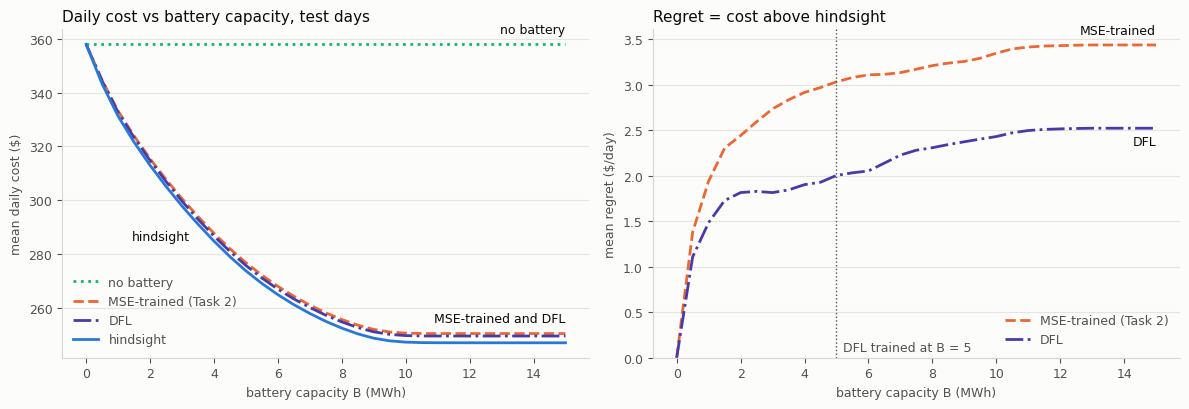

In [37]:
SER_DFL = "#4a3aa7"   # DFL series; MSE keeps SER["pred"], hindsight SER["hind"], as in 2.2


def plot_dfl_vs_mse(sw, path=None):
    """Left: mean daily cost against capacity. Right: regret, where the two models separate."""
    fig, (ax, ax_r) = plt.subplots(1, 2, figsize=(12, 4.2), facecolor=SURFACE)
    last = sw.iloc[-1]

    _style(ax)
    ax.plot(sw["B"], sw["nobat"], color=SER["nobat"], lw=2, ls=":", label="no battery")
    ax.plot(sw["B"], sw["mse"], color=SER["pred"], lw=2, ls="--", label="MSE-trained (Task 2)")
    ax.plot(sw["B"], sw["dfl"], color=SER_DFL, lw=2, ls="-.", label="DFL")
    ax.plot(sw["B"], sw["hind"], color=SER["hind"], lw=2, label="hindsight")
    for key, txt in (("nobat", "no battery"), ("mse", "MSE-trained and DFL")):
        ax.annotate(txt, (last["B"], last[key]), color=INK, fontsize=9, ha="right", va="bottom",
                    xytext=(0, 6), textcoords="offset points")
    mid = sw.iloc[len(sw) // 4]      # hindsight is the lowest curve: label it from below-left
    ax.annotate("hindsight", (mid["B"], mid["hind"]), color=INK, fontsize=9, ha="right", va="top",
                xytext=(-6, -4), textcoords="offset points")
    ax.set_xlabel("battery capacity B (MWh)", fontsize=9, color=INK_MUTED)
    ax.set_ylabel("mean daily cost ($)", fontsize=9, color=INK_MUTED)
    ax.set_title("Daily cost vs battery capacity, test days", fontsize=11, color=INK, loc="left")
    ax.legend(frameon=False, fontsize=9, labelcolor=INK_MUTED, loc="lower left")

    _style(ax_r)
    ax_r.plot(sw["B"], sw["regret_mse"], color=SER["pred"], lw=2, ls="--", label="MSE-trained (Task 2)")
    ax_r.plot(sw["B"], sw["regret_dfl"], color=SER_DFL, lw=2, ls="-.", label="DFL")
    ax_r.axvline(B_DEFAULT, color=INK_MUTED, lw=1, ls=":")
    ax_r.annotate("DFL trained at B = %g" % B_DEFAULT, (B_DEFAULT, 0), color=INK_MUTED, fontsize=9,
                  xytext=(5, 5), textcoords="offset points")
    upper = "mse" if last["regret_mse"] >= last["regret_dfl"] else "dfl"
    for key, txt in (("mse", "MSE-trained"), ("dfl", "DFL")):
        ax_r.annotate(txt, (last["B"], last["regret_" + key]), color=INK, fontsize=9, ha="right",
                      va="bottom", xytext=(0, 6 if key == upper else -14), textcoords="offset points")
    ax_r.set_ylim(bottom=0)
    ax_r.set_xlabel("battery capacity B (MWh)", fontsize=9, color=INK_MUTED)
    ax_r.set_ylabel("mean regret ($/day)", fontsize=9, color=INK_MUTED)
    ax_r.set_title("Regret = cost above hindsight", fontsize=11, color=INK, loc="left")
    ax_r.legend(frameon=False, fontsize=9, labelcolor=INK_MUTED, loc="lower right")

    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


# `sweep` (2.2 Step 9) already holds no battery / MSE-trained / hindsight on B_VALUES,
# so only the DFL schedules need solving. One DFL model, trained at B_DEFAULT, scored at every B.
sweep_dfl = sweep[["B", "nobat", "hind"]].copy()
sweep_dfl["mse"] = sweep["pred"]
sweep_dfl["dfl"] = [score_forecast(p_hat_dfl_k, p_true_k, D, B)["cost_pred"].mean() for B in B_VALUES]
sweep_dfl["regret_mse"] = sweep_dfl["mse"] - sweep_dfl["hind"]
sweep_dfl["regret_dfl"] = sweep_dfl["dfl"] - sweep_dfl["hind"]
sweep_dfl["dfl - mse"] = sweep_dfl["dfl"] - sweep_dfl["mse"]

print(sweep_dfl[sweep_dfl["B"].isin([0, 2, 5, 10, 15])].round(3).to_string(index=False))

plot_dfl_vs_mse(sweep_dfl, VIS_DIR / "cost_vs_capacity_dfl_vs_mse.png")
plt.show()

### Sensitivity to the regularisation weight $\epsilon$


In [38]:
EPS_TRAIN = [0.1, 0.2, 0.3, 0.5, 1.0]


def score_model(name, m, B=B_DEFAULT):
    """Validation cost, and test cost / regret / captured share, all with the true LP."""
    p_hat_m = expected_price(predict(m, splits["test"]["Z"])[keep], sigma2)
    r = score_forecast(p_hat_m, p_true_k, D, B)
    return {"model": name, "val LP cost ($/day)": lp_cost(m, splits["val"], B),
            "test cost ($/day)": r["cost_pred"].mean(), "test regret ($/day)": r["regret"].mean(),
            "captured": captured(r)}


dfl_runs = {}
rows = [score_model("MSE (Task 2)", model)]
for eps in EPS_TRAIN:
    print(f"\n--- eps = {eps:g} ---")
    torch.manual_seed(SEED)               # same batch order and dropout masks for every run
    dfl_runs[eps] = train_dfl(copy.deepcopy(model), eps=eps)
    rows.append(score_model(f"DFL, eps = {eps:g}", dfl_runs[eps]))

eps_results = pd.DataFrame(rows).set_index("model")
print("\nB = %.1f MWh, %d test days, test hindsight cost %.3f $/day"
      % (B_DEFAULT, len(res), res["cost_hind"].mean()))
print(eps_results.round(3).to_string())


--- eps = 0.1 ---
start      val LP cost 295.552  (MSE-trained model, before DFL)
epoch   0  train loss 417.736  val LP cost 295.464
epoch   1  train loss 435.808  val LP cost 295.351
epoch   2  train loss 432.341  val LP cost 295.390
epoch   3  train loss 422.183  val LP cost 295.711
epoch   4  train loss 404.894  val LP cost 295.802
epoch   5  train loss 426.906  val LP cost 295.738
epoch   6  train loss 392.372  val LP cost 295.593
early stopping at epoch 6, best val LP cost 295.351

--- eps = 0.2 ---
start      val LP cost 295.552  (MSE-trained model, before DFL)
epoch   0  train loss 417.615  val LP cost 295.712
epoch   1  train loss 435.826  val LP cost 295.667
epoch   2  train loss 432.096  val LP cost 295.778
epoch   3  train loss 422.011  val LP cost 295.939
epoch   4  train loss 404.804  val LP cost 295.866
early stopping at epoch 4, best val LP cost 295.552

--- eps = 0.3 ---
start      val LP cost 295.552  (MSE-trained model, before DFL)
epoch   0  train loss 417.861  val 

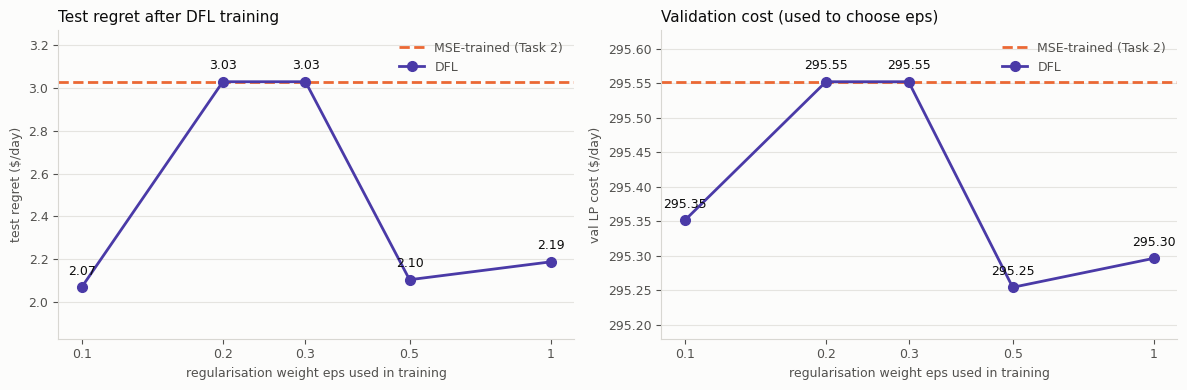

In [39]:
def plot_eps_sensitivity(results, eps_values, path=None):
    """Test regret and validation cost of the DFL runs against eps, with the MSE-trained model as reference."""
    base, runs = results.iloc[0], results.iloc[1:]
    panels = (("test regret ($/day)", "Test regret after DFL training"),
              ("val LP cost ($/day)", "Validation cost (used to choose eps)"))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), facecolor=SURFACE)
    for ax, (col, title) in zip(axes, panels):
        _style(ax)
        ax.axhline(base[col], color=SER["pred"], lw=2, ls="--", label="MSE-trained (Task 2)")
        ax.plot(eps_values, runs[col], color=SER_DFL, lw=2, marker="o", ms=7, label="DFL")
        for e, v in zip(eps_values, runs[col]):
            ax.annotate("%.2f" % v, (e, v), color=INK, fontsize=9, ha="center", va="bottom",
                        xytext=(0, 7), textcoords="offset points")
        ax.set_xscale("log")
        ax.set_xticks(eps_values)
        ax.set_xticklabels(["%g" % e for e in eps_values])
        ax.minorticks_off()
        lo, hi = min(runs[col].min(), base[col]), max(runs[col].max(), base[col])
        pad = 0.25 * max(hi - lo, 1e-6)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_xlabel("regularisation weight eps used in training", fontsize=9, color=INK_MUTED)
        ax.set_ylabel(col, fontsize=9, color=INK_MUTED)
        ax.set_title(title, fontsize=11, color=INK, loc="left")
        ax.legend(frameon=False, fontsize=9, labelcolor=INK_MUTED, loc="best")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, facecolor=SURFACE, bbox_inches="tight")
    return fig


plot_eps_sensitivity(eps_results, EPS_TRAIN, VIS_DIR / "dfl_eps_sensitivity.png")
plt.show()

### Where DFL still loses money (quick look)

A quick look, not polished for the report. It runs the 4.1 diagnostics on the DFL model and compares
it with the MSE model on the same test days, at $B$ = `B_DEFAULT`. It answers four questions: did DFL
shrink the tail or the typical day, which days it fixed or broke, what the remaining worst days look
like, and where in the day and year the regret sits. Every schedule is solved with the true LP, as in 2.2.


In [40]:
# The DFL model to inspect: the eps with the lowest validation cost. Swap in model_dfl or dfl_runs[e] freely.
eps_pick = min(dfl_runs, key=lambda e: eps_results.loc[f"DFL, eps = {e:g}", "val LP cost ($/day)"])
m_x = dfl_runs[eps_pick]
p_hat_x = expected_price(predict(m_x, splits["test"]["Z"])[keep], sigma2)
lab_x = f"DFL eps={eps_pick:g}"

diag_x = day_diagnostics(p_hat_x, p_true_k, D, B_DEFAULT, dates_k)
diag_x["month"] = pd.to_datetime(diag_x["date"]).dt.month

# 1. Did DFL shrink the tail, or only the typical day?
print("Regret per test day ($/day), B = %.1f MWh" % B_DEFAULT)
print(pd.DataFrame({"MSE": regret_stats(diag["regret"]), lab_x: regret_stats(diag_x["regret"])}).T
        .round(3).to_string())

# 2. Day by day: which days did DFL fix, which did it break?
cmp = pd.DataFrame({
    "date": diag["date"], "month": diag_x["month"],
    "regret_mse": diag["regret"], "regret_dfl": diag_x["regret"],
    "saving_hind": diag["saving_hind"], "true_spread": diag["true_spread"],
    "bias_mse": diag["bias"], "bias_dfl": diag_x["bias"],
    "rank_mse": diag["rank_corr"], "rank_dfl": diag_x["rank_corr"],
})
cmp["delta"] = cmp["regret_dfl"] - cmp["regret_mse"]
tol = 1e-3
better, worse = cmp["delta"] < -tol, cmp["delta"] > tol
print("\nDFL better on %d days (saved $%.2f in total), worse on %d (lost $%.2f), unchanged on %d"
      % (better.sum(), -cmp.loc[better, "delta"].sum(), worse.sum(),
         cmp.loc[worse, "delta"].sum(), (~better & ~worse).sum()))
show = ["date", "regret_mse", "regret_dfl", "delta", "true_spread", "bias_mse", "bias_dfl", "rank_mse", "rank_dfl"]
print("\nMost improved days:")
print(cmp.nsmallest(5, "delta")[show].round(2).to_string(index=False))
print("\nMost worsened days:")
print(cmp.nlargest(5, "delta")[show].round(2).to_string(index=False))

# 3. What did DFL change in the forecast itself? Mean shift per hour, $/MWh.
shift = pd.DataFrame({"DFL - MSE forecast": (p_hat_x - p_hat_k).mean(axis=0),
                      "MSE bias": (p_hat_k - p_true_k).mean(axis=0),
                      "DFL bias": (p_hat_x - p_true_k).mean(axis=0)},
                     index=pd.RangeIndex(T, name="hour"))
print("\nMean forecast shift and bias per hour ($/MWh):")
print(shift.round(2).T.to_string())


Regret per test day ($/day), B = 5.0 MWh
              mean    P50    P90    P95     P99     max  worst 5% share  worst 10% share
MSE          3.030  1.630  6.288  8.956  31.477  44.825           0.331            0.451
DFL eps=0.5  2.103  1.111  4.580  6.747  17.153  32.348           0.299            0.433

DFL better on 214 days (saved $488.25 in total), worse on 64 (lost $84.42), unchanged on 158

Most improved days:
      date  regret_mse  regret_dfl  delta  true_spread  bias_mse  bias_dfl  rank_mse  rank_dfl
2016-06-26       44.83        2.31 -42.51        41.91      2.03      2.12      0.99      0.99
2016-01-26       41.62        7.98 -33.64        23.46      6.89      6.95      0.77      0.82
2016-06-19       34.21        1.31 -32.90        41.74      4.89      4.98      0.99      0.99
2016-12-19       39.68       15.06 -24.62        41.94     -9.11     -9.01      0.90      0.90
2016-01-18       19.19        1.38 -17.81        41.59      8.44      8.56      0.88      0.93

Most w

In [41]:
# 4. The remaining worst days under DFL, and whether they are the same days as under MSE.
worst_x = diag_x["regret"].sort_values(ascending=False).index[:N_WORST]
tbl = diag_x.loc[worst_x, cols].copy()
tbl.insert(2, "regret_mse", diag.loc[worst_x, "regret"])
print("Worst %d days under %s (B = %.1f MWh)" % (N_WORST, lab_x, B_DEFAULT))
print(tbl.round(2).to_string(index=False))
print("\n%d of these were also among the worst %d under MSE" % (len(set(worst_x) & set(worst_idx)), N_WORST))

# 5. Hours of the day where the regret is incurred (sums to the group's mean regret).
contrib_x = pd.DataFrame({
    "DFL worst 10": hourly_regret(diag_x, p_true_k, worst_x),
    "DFL all days": hourly_regret(diag_x, p_true_k, diag_x.index),
    "MSE all days": hourly_regret(diag, p_true_k, diag.index),
}, index=pd.RangeIndex(T, name="hour"))
print("\nPer-hour contribution to regret ($/day):")
print(contrib_x.round(2).T.to_string())

# 6. What still goes with regret under DFL?
print("\nSpearman correlation with DFL regret:")
print(pd.Series({c: spearmanr(diag_x[c], diag_x["regret"])[0] for c in corr_cols}).round(3).to_string())

# 7. Season.
by_month_x = pd.DataFrame({
    "days": diag_x.groupby("month").size(),
    "MSE mean regret": diag.groupby("month")["regret"].mean(),
    "DFL mean regret": diag_x.groupby("month")["regret"].mean(),
    "DFL max regret": diag_x.groupby("month")["regret"].max(),
    "mean spread": diag_x.groupby("month")["true_spread"].mean(),
})
print("\nBy month ($/day):")
print(by_month_x.round(2).to_string())


Worst 10 days under DFL eps=0.5 (B = 5.0 MWh)
      date  regret  regret_mse  saving_hind  lost_share  rmse  bias  shape_rmse  rank_corr  trough_miss  hour_true_min  hour_pred_min  true_spread  x_l1_diff
2016-02-15   32.35       34.40        64.13        0.50  9.32  6.96        6.20       0.72         2.64              9             20        29.77      13.23
2016-02-14   24.10       26.41        57.69        0.42 16.74 13.39       10.05       0.68         0.00             20             20        34.74      13.04
2016-06-13   18.91       20.70       128.17        0.15  2.57  1.69        1.93       0.98         3.57              7              8        31.46      11.02
2016-01-23   18.42       17.48        63.52        0.29  2.31 -0.40        2.28       0.85         3.11              4             11        17.04      16.74
2016-01-13   18.28        3.43       108.34        0.17  6.93  5.04        4.75       0.89         2.97              4              3        43.34      14.26
2016-1

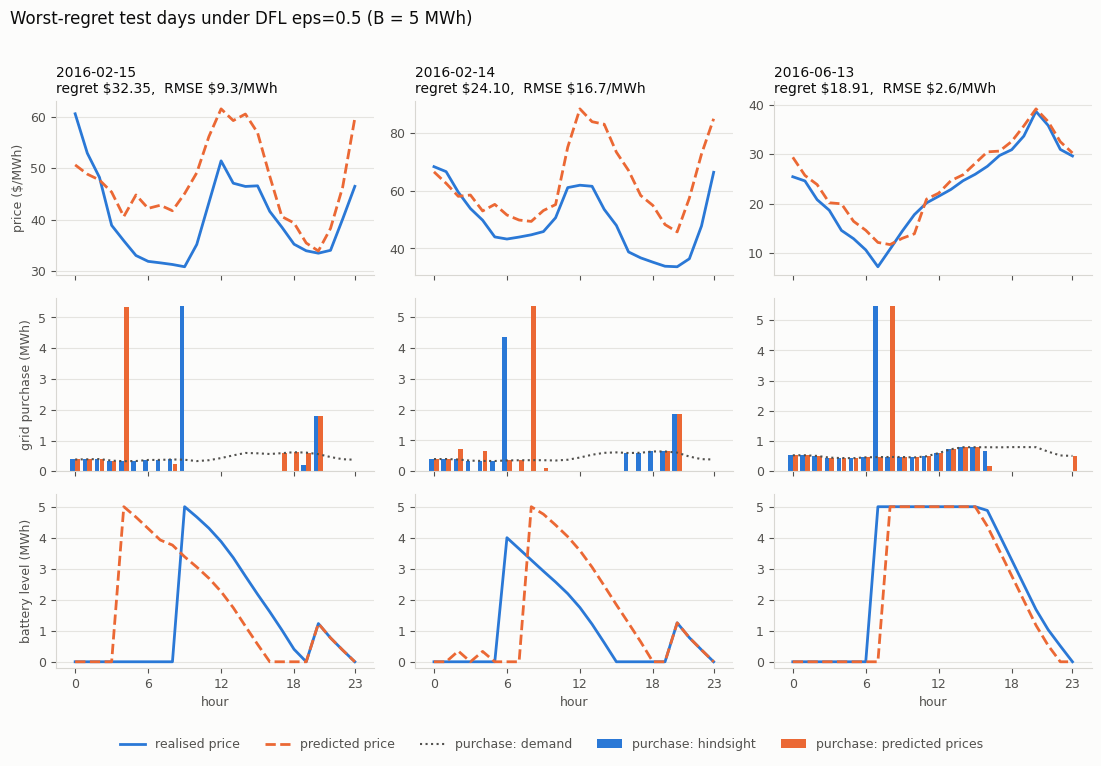

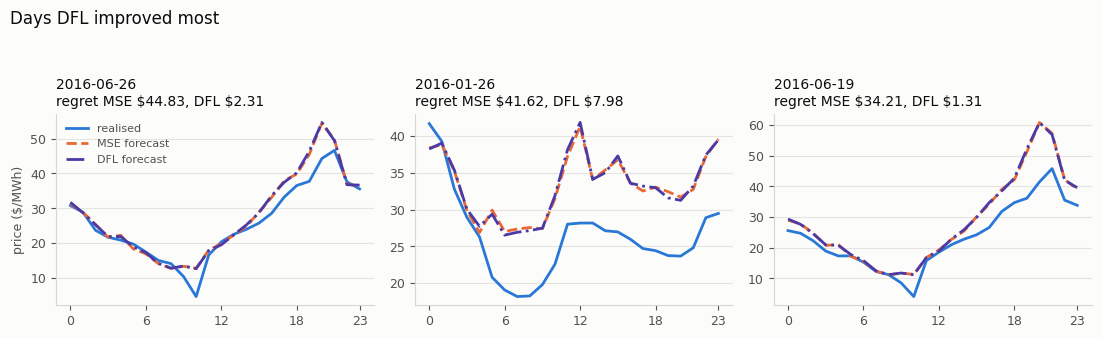

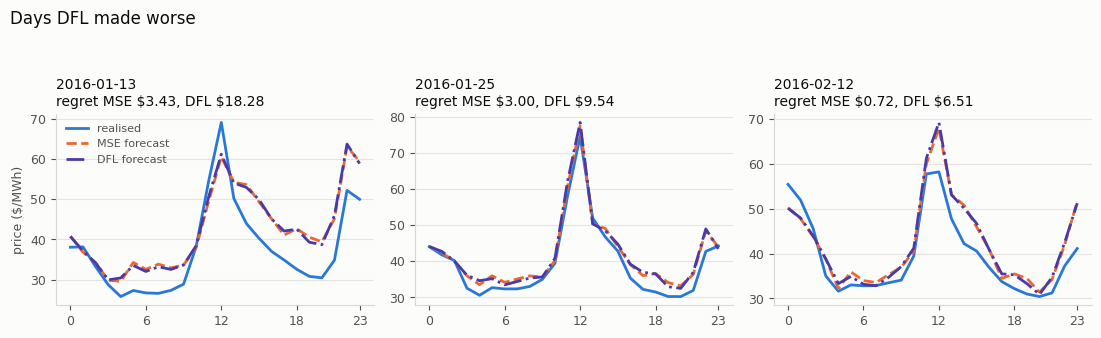

In [42]:
# Pictures: the 3 worst DFL days (same layout as 4.1), then the days DFL changed most, both forecasts overlaid.
plot_worst_days(worst_x[:3], diag_x, p_hat_x, p_true_k, D, B_DEFAULT,
                f"Worst-regret test days under {lab_x} (B = {B_DEFAULT:g} MWh)")


def plot_changed_days(idx, title):
    hours = np.arange(T)
    fig, axes = plt.subplots(1, len(idx), figsize=(3.7 * len(idx), 3.4), sharex=True, facecolor=SURFACE)
    for ax, i in zip(np.atleast_1d(axes), idx):
        _style(ax)
        ax.plot(hours, p_true_k[i], color=SER["hind"], lw=2, label="realised")
        ax.plot(hours, p_hat_k[i], color=SER["pred"], lw=2, ls="--", label="MSE forecast")
        ax.plot(hours, p_hat_x[i], color=SER_DFL, lw=2, ls="-.", label="DFL forecast")
        r = cmp.loc[i]
        ax.set_title(f"{r['date']}\nregret MSE \${r['regret_mse']:.2f}, DFL \${r['regret_dfl']:.2f}",
                     fontsize=10, color=INK, loc="left")
        ax.set_xticks([0, 6, 12, 18, 23])
    np.atleast_1d(axes)[0].set_ylabel("price (\$/MWh)", fontsize=9, color=INK_MUTED)
    np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8, labelcolor=INK_MUTED, loc="best")
    fig.suptitle(title, fontsize=12, color=INK, x=0.012, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    return fig


plot_changed_days(cmp.nsmallest(3, "delta").index, "Days DFL improved most")
plot_changed_days(cmp.nlargest(3, "delta").index, "Days DFL made worse")
plt.show()
